In [1]:
import logging

import numpy as np
import optimistix as optx

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

from scipy.interpolate import interp1d
from scipy.optimize import fsolve, root_scalar
import os

import seaborn as sns
import corner
import pandas as pd
from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_useOffset(False)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable


In [2]:
plt.rc('font',   size=16)          # controls default text sizes
plt.rc('axes',   titlesize=18)     # fontsize of the axes title
plt.rc('axes',   labelsize=18)     # fontsize of the x and y labels
plt.rc('xtick',  labelsize=18)     # fontsize of the tick labels
plt.rc('ytick',  labelsize=18)     # fontsize of the tick labels
plt.rc('legend', fontsize=18)      # legend fontsize
plt.rc('figure', titlesize=18)     # fontsize of the figure title

In [3]:
color_tot = "black"
color_H2 = "orange"
color_H2O = "blue"
color_SiH4 = "red"
color_SiO2 = "yellow"
color_SiO = "brown"
color_O2 = "limegreen"
color_CO2 = "cyan"
color_CO = "magenta"
color_CH4 = "purple"
color_N2 = "green"
color_NH3 = "pink"
color_MgO = "darkred"
color_He = "gray"
color_H = "orange"
color_C = "cyan"
color_N = "green"
color_O = "blue"
color_Si = "red"
color_Mg = "lime"
color_MgH2 = "gold"
color_MgH = "teal"
color_MgOH = "indigo"
color_Ccr = "dimgray"

In [4]:
SiO2_mantlemasspercent_palme14: float = 45.4
total_mantlemasspercent_palme14: float = 98.41
core_mass_fraction: float = 0.327  # typical values used are between 0.325 - 0.33
Si_massfraction_palme14: float = round(
    SiO2_mantlemasspercent_palme14
    / total_mantlemasspercent_palme14
    * (1 - core_mass_fraction)
    / (28.0855 + 2 * 15.999)
    * 28.0855,
    3,
)

O_massfraction_palme14: float = Si_massfraction_palme14 / 28.0855 * 2 * 15.999
# Lodders et al. (2009) Springer Book Chapter - Table 8 (in wt%)

H_masspercent_lodders09: float = 73.9
He_masspercent_lodders09: float = 24.69
C_masspercent_lodders09: float = 0.22
N_masspercent_lodders09: float = 0.07
O_masspercent_lodders09: float = 0.63
Si_masspercent_lodders09: float = 0.07
Mg_masspercent_lodders09: float = 0.06

# Lodders et al. (2009) Springer Book Chapter - Table 6 (log-normalalized abundances relative to H)

H_logN: float = 12
He_logN: float = 10.93
C_logN: float = 8.39
N_logN: float = 7.86
O_logN: float = 8.73
Si_logN: float = 7.53
Mg_logN: float = 7.54 

In [5]:
number_of_realisations = 50

# Overall structure 
R_earth = 6.371e6
R_uranus = 3.939 * R_earth
M_earth = 5.972e24 #kg
M_uranus = 14.536 * M_earth

#fO2_log10_shifts = [-1]
fO2_log10_shifts = np.linspace(-6, 0, num=30)  # IW-6 to IW
fO2_log10_shifts = [-6,-5,-4,-3,-2,-1,0]
hmps = np.logspace(-1,0, num=50)  # wt% H
h_kgs = hmps / 100 * M_uranus  # kg

si_kgs_solar = h_kgs * Si_masspercent_lodders09 / H_masspercent_lodders09
mg_kgs_solar = h_kgs * Mg_masspercent_lodders09 / H_masspercent_lodders09
o_kgs_solar = h_kgs * O_masspercent_lodders09 / H_masspercent_lodders09
c_kgs_solar = h_kgs * C_masspercent_lodders09 / H_masspercent_lodders09
n_kgs_solar = h_kgs * N_masspercent_lodders09 / H_masspercent_lodders09
he_kgs_solar = h_kgs * He_masspercent_lodders09 / H_masspercent_lodders09


rho_centres = [2500,3000,2000,1500,1000]
rho_centres = [3000]
rho_centre = 3000
print(rho_centres)
R_core = 0.7*R_uranus
Lowerbound_M_core = [
    4*np.pi*(R_core**3)*rho/3
    for rho in rho_centres
]
M_cores = Lowerbound_M_core
print(M_cores)

[3000]
[6.812158460855618e+25]


In [6]:
f = 1/4

T_solar = 5772
R_solar = 6.957e8
d_solar_Uranus = 2876679082000

T_irr = T_solar * np.sqrt(R_solar/d_solar_Uranus)

T_eff = 59.1 #pm 0.3 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_eq = 58.2 #pm 1 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_int = (T_eff**(4) - T_eq**(4))**(1/4)
#T_int = 120


gamma_1 = 0.01
gamma_2 = 2
gamma_3 = 0.1
gammas = np.logspace(-4,2,7)
gamma = gamma_2
tau = np.logspace(-10,10,1000)

In [7]:
def Temp_profile(tau, T_int, gamma):
    #This function gives back a Temperature, given optical depth, gamma and intrinsic temperature
    #tau : give an optical depth
    #T_int : give the intrinsic temperature
    #T_irr : taken to be constant along this short evolutionary track
    #gamma : gamme based on opacities of visible on thermal
    return (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)  

def find_tau(tau,T_int, gamma, target, initial_guess):
    #This function gives back the optical depth at which a certain temperature can be found, given several parameters
    #tau: space of optical depths to go over
    #T_int : intrinsic temperature
    #gamma : gives the gamma 
    #target: the target temperature
    #intial_guess : your initial guess for the optical depth
    def g(tau):
        return Temp_profile(tau,T_int, gamma) - target
    x_solution = fsolve(g, initial_guess)
    return x_solution[0]

def find_gamma(tau,T_int, gamma, target, initial_guess):
    #This function gives back the gamma at which a certain temperature can be found, given several parameters
    #tau: optical depth at which it is found
    #T_int : intrinsic temperature
    #gamma : gammas to loop over
    #target: the target temperature
    #intial_guess : your initial guess for the optical depth
    def h(gamma):
        return Temp_profile(tau,T_int, gamma) - target
    x_solution = fsolve(h, initial_guess)
    return x_solution[0]
def find_scale(Temperature,T_int,gamma, Pressure, tau, initial_guess):
    #Probably will not be used in the future, finds how optical depth and Pressure are scaled
    #Temperature: gives the temperature at which to calculate the scaling
    #T_int : intrinsic temperature
    #gamma : gamma
    #Pressure: gives the pressure at which to calculate the scaling 
    #denotes the optical depths to loop over 
    #intiial guess for optical depth
    tau_scale = find_tau(tau,T_int,gamma, Temperature, initial_guess)
    scale_factor = Pressure/tau_scale
    return scale_factor

def find_Tint(tau,T_int, gamma, target, initial_guess):
    #This function gives back the T_intr at which a certain temperature can be found, given several parameters
    #tau: optical depth at which it is found
    #T_int : intrinsic temperature to loop over
    #gamma : gamma
    #target: the target temperature
    #intial_guess : your initial guess for the optical depth
    def ze(T_int):
        return Temp_profile(tau,T_int, gamma) - target
    x_solution = fsolve(ze, initial_guess)
    return x_solution[0]
    

def Pressure_Temperatures(T_original, T_int,gamma, tau, Pressure, initial_guess):
    #Gives Pressures/Temperatures profiles given different parameters
    #T_original: Temperature where we know the pressures
    #T_int : the intrinisic temperatures
    #gamma : gamma 
    #tau: optical depths to find over 
    #Pressure: pressure where we know the temperature
    #intial_guess : initial guess for optical depth
    scales = find_scale(T_original, T_int, Pressure, tau, initial_guess)
    Pressures = tau*scales
    Temperatures = Temp_profile(tau, T_int,gamma)
    indices = [i for i, v in enumerate(Temperatures) if 0 < v < 6000]
    return Pressures[indices], Temperatures[indices]

In [8]:
def peridotite_solidus(P_bar): #On the cooling of a deep terrestrial magma ocean
    #P_bar: pressure in bar
    #Returns: solidus temperature in K
    P_Pa = P_bar*10**5
    T_sol = 1661.2*((P_Pa/(1.336*10**9))+1)**(1/7.437)
    return T_sol

def peridotite_liquidus(P_bar):
    #P_bar: pressure in bar
    #Returns: liquidus temperature in K
    P_Pa = P_bar*10**5
    T_liq = 1982.1*((P_Pa/(6.594*10**9))+1)**(1/5.374)
    
    return T_liq

In [9]:
def opacity(P, T, met): 
    #GASEOUS MEAN OPACITIES FOR GIANT PLANET AND ULTRACOOL DWARF ATMOSPHERES OVER A RANGE OF METALLICITIES AND TEMPERATURES
    #P in bar 
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    c1 = 10.602
    c2 = 2.882
    c3 = 6.09e-15
    c4 = 2.954
    c5 = -2.526
    c6 = 0.843
    c7 = -5.490
    
    c8low = -14.051
    c9low = 3.055
    c10low = 0.024
    c11low = 1.877
    c12low = -0.445
    c13low = 0.8321
    
    c8high =  82.241
    c9high = -55.456
    c10high = 8.754 
    c11high = 0.7048
    c12high = -0.0414
    c13high = 0.8321

    if P <= 0 or T <= 0:
        return np.inf
    kappa_low_P = c1*np.arctan(np.log10(T)-c2) - (c3*np.exp((np.log10(T)-c5)**2)/(np.log10(P)+c4)) +c6*met +c7
    if T <= 800:
        kappa_high_P = c8low + c9low*np.log10(T)+c10low*(np.log10(T)**2)+ (c11low + c12low*np.log10(T))*np.log10(P) + c13low*met*(0.5 + (np.arctan(5*np.log10(T)-12.5)/np.pi))
    else:
        kappa_high_P = c8high + c9high*np.log10(T)+c10high*(np.log10(T)**2)+ (c11high + c12high*np.log10(T))*np.log10(P) + c13high*met*(0.5 + (np.arctan(5*np.log10(T)-12.5)/np.pi))
    
    kappa_final = 10**(kappa_low_P) + 10**(kappa_high_P)

    return kappa_final

def optical_depth_finder(P, T, met, surf_grav):
    #Function that gives back optical depths
    #P in cgs
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    opt_depth = P*opacity(P, T, met)/surf_grav
    return opt_depth

def optical_depth_finder_given_opacity(P, opacity, surf_grav):
    #Function that gives back optical depths
    #P in cgs
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    opt_depth = P*opacity/surf_grav
    return opt_depth

def pressure_finder(optical_depths, T, met, surf_grav, initial_guess):
    #optical depths 
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    #gives back pressure in dyne/cm^2
    def az(press):
        return optical_depth_finder(press, T, met, surf_grav) - optical_depths
    x_solution = fsolve(az, initial_guess)
    return x_solution[0]

def pressure_finder_given_opacity(optical_depths, opacity, surf_grav):
    #optical depths 
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    #gives back pressure in dyne/cm^2
    pressi = optical_depths*surf_grav/opacity
    return pressi

In [10]:
def Profile_From_1_bar(Temp_at_1bar, grav_at_1bar, metalli, grid_resolution,T_max):
    #Creates a Pressure-Temperature profile from temperatures at 1 bar. 
    #Temp_at_1bar : The temperature at 1 bar level
    #grav_at_1bar : The gravity at the 1 bar level, please in cgs
    #metalli: metallicit in [M/H]
    #grid_resolution : how much space you want 
    #T_max : at some temperatures our later simulations will fail, therefor define a T_max

    Press_1bar_to_cgs = 10**6 #to dyne/cm^2, this is Pressure of 1bar in dyne/cm^2
    
    #Step 1: deduce optical depth at 76K level, the Uranus we know of today 
    optical_depth_76K = optical_depth_finder(Press_1bar_to_cgs, 76, metalli,grav_at_1bar)
#    print(f"Optical depth at 76K in Uranus as of today: {optical_depth_76K}")
    
    #Step 2: deduce an estimation for gamma 
    gammas = np.logspace(-2,0,1000)
    T_eff_final = 59.1 
    T_eq_final = 58.2
    T_int_final = (T_eff_final**(4) - T_eq_final**(4))**(1/4)
    final_gamma = find_gamma(optical_depth_76K,T_int_final, gammas, 76, 0.3)
#    print(f"The gamma to be used is : {final_gamma}")
    
    #Step 3: deduce the optical depth at which our 1bar-level is
    optical_depth_our_case = Press_1bar_to_cgs*opacity(Press_1bar_to_cgs, Temp_at_1bar, metalli)/grav_at_1bar
    thermal_opacity = opacity(Press_1bar_to_cgs, Temp_at_1bar, metalli)
#    print(f"The optical depth at 1 bar in our model: {optical_depth_our_case}")

    #Step 4: deduce which intrinsic Temperature is needed to recover this optical depth at this Pressure and Temperature
    T_int_lin = np.linspace(29,500,1000)
    Tint = find_Tint(optical_depth_our_case,T_int_lin, final_gamma, Temp_at_1bar, 50)
#    print(f"The intrinsic temperature {Tint} in our model")

    #Step 5: Using an upper and lower limit on temperature, find the max optical depth and minimal optical depth
    possible_depths = np.logspace(-10,10,1000)
    final_optical_depth  = find_tau(possible_depths,Tint, final_gamma, T_max, 1e5)
#    print(f"The optical depth until we go {final_optical_depth}")

    #Step 6, over the different optical depths, find all the temperatures
    all_optical_depths = np.logspace(-1,np.log10(final_optical_depth),grid_resolution)
    All_Temperatures = Temp_profile(all_optical_depths, Tint,final_gamma)
#    print(All_Temperatures)
    All_pressures = []
    #Step 7, at different optical depths find different pressures
    for i in range(len(all_optical_depths)):
        aze = pressure_finder_given_opacity(all_optical_depths[i], thermal_opacity, grav_at_1bar)/(10**6)
        #aze = pressure_finder(all_optical_depths[i], All_Temperatures[i], metalli, grav_at_1bar, 1e13)/(10**6)
        All_pressures.append(aze)
#        print(f"At optical depth {all_optical_depths[i]} and Temperature {All_Temperatures[i]}K we have pressures {aze}")

    #Extra Step ~ Find effective temperature 
    T_eq = 58.2 #pm 1 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
    T_eff_end = (Tint**(4) + T_eq**(4))**(1/4)
    return All_Temperatures, All_pressures, Tint, T_eff_end

In [11]:
def Pressure_at_Temperature_From_1_bar(Temp_at_1bar, grav_at_1bar, metalli, T_forpress):
    #Creates a Pressure-Temperature profile from temperatures at 1 bar and then tries to find the Pressure at a given temperature
    #Temp_at_1bar : The temperature at 1 bar level
    #grav_at_1bar : The gravity at the 1 bar level, please in cgs
    #metalli: metallicit in [M/H]
    #grid_resolution : how much space you want 
    #T_max : at some temperatures our later simulations will fail, therefor define a T_max

    Press_1bar_to_cgs = 10**6 #to dyne/cm^2, this is Pressure of 1bar in dyne/cm^2
    
    #Step 1: deduce optical depth at 76K level, the Uranus we know of today 
    optical_depth_76K = optical_depth_finder(Press_1bar_to_cgs, 76, metalli,grav_at_1bar)
#    print(f"Optical depth at 76K in Uranus as of today: {optical_depth_76K}")
    
    #Step 2: deduce an estimation for gamma 
    gammas = np.logspace(-2,0,1000)
    T_eff_final = 59.1 
    T_eq_final = 58.2
    T_int_final = (T_eff_final**(4) - T_eq_final**(4))**(1/4)
    final_gamma = find_gamma(optical_depth_76K,T_int_final, gammas, 76, 0.3)
#    print(f"The gamma to be used is : {final_gamma}")
    
    #Step 3: deduce the optical depth at which our 1bar-level is
    optical_depth_our_case = Press_1bar_to_cgs*opacity(Press_1bar_to_cgs, Temp_at_1bar, metalli)/grav_at_1bar
    thermal_opacity = opacity(Press_1bar_to_cgs, Temp_at_1bar, metalli)
#    print(f"The optical depth at 1 bar in our model: {optical_depth_our_case}")

    #Step 4: deduce which intrinsic Temperature is needed to recover this optical depth at this Pressure and Temperature
    T_int_lin = np.linspace(29,500,1000)
    Tint = find_Tint(optical_depth_our_case,T_int_lin, final_gamma, Temp_at_1bar, 50)
#    print(f"The intrinsic temperature {Tint} in our model")

    #Step 5: Using an upper and lower limit on temperature, find the max optical depth and minimal optical depth
    possible_depths = np.logspace(-10,10,1000)
    final_optical_depth  = find_tau(possible_depths,Tint, final_gamma, T_forpress, 1e5)
#    print(f"The optical depth until we go {final_optical_depth}")

    aze = pressure_finder_given_opacity(final_optical_depth, thermal_opacity, grav_at_1bar)/(10**6)
    return aze

def Find_atm_T(P, T, met, surf_grav):
    def test_find_atm_T(atmo_T):
        return Pressure_at_Temperature_From_1_bar(atmo_T, surf_grav, met,T) - P
    T_atmo_1bar = fsolve(test_find_atm_T, 1e2)
    return T_atmo_1bar[0]
def Pressure_and_Temperature_to_profile(P, T, met, surf_grav,grid_resolution):
    #Creates pressure and temperature profile given one pressure and temperature
    #optical depths 
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    #P in bar
    T_atmo_1bar = Find_atm_T(P, T, met, surf_grav)
    All_Temperatures, All_pressures, Tint, T_eff_end = Profile_From_1_bar(T_atmo_1bar, surf_grav, met, grid_resolution,T)
    return All_Temperatures, All_pressures, Tint, T_eff_end, T_atmo_1bar

In [12]:
def Find_T_from_atmo_and_Pressure(T_at_1bar, Pressure_at_layer, met, surf_grav):
    #Finds the Temperature when given atmospheric temperature at 1 bar and pressure
    #T_at_1bar, the temperature at the 1 bar level
    #The pressure at our starting layer,
    #met metallicity as in [M/H] 
    #surf_grav, surface gravity woop

    Press_1bar_to_cgs = 10**6 #to dyne/cm^2, this is Pressure of 1bar in dyne/cm^2
    
    #Step 1: deduce optical depth at 76K level, the Uranus we know of today 
    optical_depth_76K = optical_depth_finder(Press_1bar_to_cgs, 76, met,surf_grav)
#    print(f"Optical depth at 76K in Uranus as of today: {optical_depth_76K}")
    
    #Step 2: deduce an estimation for gamma 
    gammas = np.logspace(-2,0,1000)
    T_eff_final = 59.1 
    T_eq_final = 58.2
    T_int_final = (T_eff_final**(4) - T_eq_final**(4))**(1/4)
    final_gamma = find_gamma(optical_depth_76K,T_int_final, gammas, 76, 0.3)
#    print(f"The gamma to be used is : {final_gamma}")
    
    #Step 3: deduce the optical depth at which our 1bar-level is
    optical_depth_our_case = Press_1bar_to_cgs*opacity(Press_1bar_to_cgs, T_at_1bar, met)/surf_grav
    thermal_opacity = opacity(Press_1bar_to_cgs, T_at_1bar, met)
#    print(f"The optical depth at 1 bar in our model: {optical_depth_our_case}")

    #Step 4: deduce which intrinsic Temperature is needed to recover this optical depth at this Pressure and Temperature
    T_int_lin = np.linspace(29,500,1000)
    Tint = find_Tint(optical_depth_our_case,T_int_lin, final_gamma, T_at_1bar, 50)
#    print(f"The intrinsic temperature {Tint} in our model")

    #Step 5: Deduce the optical depth needed for our pressure
    pressure_tau = optical_depth_finder_given_opacity(Pressure_at_layer*10**6, thermal_opacity, surf_grav)
    #Step 6: Given everything now, deduce the temperature at our layer
    Final_T = Temp_profile(pressure_tau, Tint, final_gamma)
    return Final_T

def Create_Temperature_Constant_Pressure(Constant_Pressure, starting_Temperature_at_layer, ending_Temperature_1bar, met, surf_grav, timesteps,grid_resolution):
    #Here we start from a temperature with a pressure there. Next we construct how that pressure evolves in time, how it cools down, while also solving
    # temperature-pressure profiles at all different timesteps
    # Tatmo returns a list of 1 bar temperatures during the timesteps
    # Solidus returns wether at that timestep we still have melt or not 
    # Tlayer returns temperatures at those layers
    # Pressures_atmo, Temperatures_atmo return the pressure-temperature profile

    #Constant Pressure: The pressure found back at our layer in bar
    #starting_Temperature_at_layer: the temperature at our layer 
    #ending_Temperature_1bar: the ending temperature, taken often 76 K
    # met metallicity as in [M/H], often taken 1.5
    #surf_grav in cgs, often 887
    #timesteps, the amount of steps in time
    #gridresolution : how many values in our atmosphere

    #Step 1: from our pressure and layer, construct a temperature-pressure profile, from this we can also get pressure at 1 bar
    Temperature_profile0, Pressure_profile0, Tint0, T_eff0, T_atmo_1bar0 = Pressure_and_Temperature_to_profile(Constant_Pressure, starting_Temperature_at_layer, met, surf_grav,grid_resolution)
    
    #Step 2: create a linspace of temperatures from then to now
    T_atmo_lin = np.linspace(T_atmo_1bar0,ending_Temperature_1bar, timesteps)

    #Step 3: Find the layers temperatures for the different 1 bar temperatures
    Tlayer = []
    for Ts in T_atmo_lin:
        Tlayer.append(Find_T_from_atmo_and_Pressure(Ts, Constant_Pressure, met, surf_grav))
    Tlayer = np.array(Tlayer)

    #Step 4: Consctruct from the different layers different pressure temperature profiles, the final state, the state as of today often gives
    #numerical errors, so we exclude it first and then calculate
    T_profiles = np.zeros((timesteps, grid_resolution))
    P_profiles = np.zeros((timesteps, grid_resolution))
    Tint_profiles = np.zeros((timesteps, 1))
    T_eff_profiles = np.zeros((timesteps, 1))
    T_atmo_1bar_profiles = np.zeros((timesteps, 1))
    Melt_profiles = np.zeros((timesteps, 1))
    
    for i in range(len(Tlayer)-1):
        Ti, Pi, Tinti, T_effi, T_atmo_1bari = Pressure_and_Temperature_to_profile(Constant_Pressure, Tlayer[i], met, surf_grav,grid_resolution)
        T_profiles[i] = Ti
        P_profiles[i] = Pi
        Tint_profiles[i] = Tinti
        T_eff_profiles[i] = T_effi
        T_atmo_1bar_profiles[i] = T_atmo_1bari

    #Step 5 construct the final layer
    T_profiles[-1], P_profiles[-1], Tint_profiles[-1], T_eff_profiles[-1] = Profile_From_1_bar(ending_Temperature_1bar, surf_grav, met, grid_resolution,Tlayer[-1])
    T_atmo_1bar_profiles[-1] = ending_Temperature_1bar

    #Step 6, for our starting layers, conclude wether magma ocean or not with solidus
    Solidus_line = peridotite_solidus(Constant_Pressure)
    for i in range(len(Tlayer)):
        if Tlayer[i] < Solidus_line:
            Melt_profiles[i] = False
        else:
            Melt_profiles[i] = True
    return Tlayer, T_atmo_1bar_profiles,T_profiles, P_profiles, Tint_profiles, T_eff_profiles, Melt_profiles

In [13]:
filename = f"/home/mathias/Margtest/Magrathea/result_final0/results.xlsx"
Radii = pd.read_excel(filename, sheet_name="Results")["Radius (earth)"]
Masses = pd.read_excel(filename, sheet_name="Results")["M (earth)"]
Temperatures_layer = pd.read_excel(filename, sheet_name="Results")["T (K)"]

Radii = Radii.iloc[::-1].reset_index(drop=True)
Masses = Masses.iloc[::-1].reset_index(drop=True)
Temperatures_layer = Temperatures_layer.iloc[::-1].reset_index(drop=True)
print(Radii)

0      2.018746
1      2.018482
2      2.018199
3      2.017922
4      2.017618
         ...   
246    1.914267
247    1.913047
248    1.911821
249    1.910866
250    1.910132
Name: Radius (earth), Length: 251, dtype: float64


In [14]:
Temperatures_layer_time = Temperatures_layer[::25]
mask = Temperatures_layer_time > 700
Temperatures_layer_time = Temperatures_layer_time[mask]
Radii_time = Radii[::25]
Radii_time = Radii_time[mask]

print(Radii_time)

0      2.018746
25     2.011287
50     2.003982
75     1.996080
100    1.987763
125    1.978904
150    1.968825
175    1.955944
200    1.935382
225    1.925382
Name: Radius (earth), dtype: float64


In [15]:
rows_gas_number = {}
rows_gas_mass = {}
rows_gas_number_density = {}
rows_dissolved_number = {}
rows_dissolved_mass = {}
rows_total_number = {}
rows_total_mass = {}
rows_pressures = {}

fO2_log10_shifts = [-5,-4,-3,-2]
rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
Temperatures_layer_time = Temperatures_layer[::25]
mask = Temperatures_layer_time > 700
Temperatures_layer_time = Temperatures_layer_time[mask]
print(Temperatures_layer_time)

for temp_layer in Temperatures_layer_time:
    rows_gas_number[temp_layer] = []
    rows_gas_mass[temp_layer] = []
    rows_gas_number_density[temp_layer] = []
    rows_dissolved_number[temp_layer] = []
    rows_dissolved_mass[temp_layer] = []
    rows_total_number[temp_layer] = []
    rows_total_mass[temp_layer] = []
    rows_pressures[temp_layer] = []
    
    for fO2_log10_shift in fO2_log10_shifts:
        shift = f"{fO2_log10_shift:.2g}"
        filename = f"./excel_Uranus_time/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_T{temp_layer:.4g}K.xlsx"
        #gas number 
        H2O_gas_number = pd.read_excel(filename, sheet_name="H2O_g")["gas_number"]
        H2_gas_number = pd.read_excel(filename, sheet_name="H2_g")["gas_number"]
        O2_gas_number = pd.read_excel(filename, sheet_name="O2_g")["gas_number"]
        SiO_gas_number = pd.read_excel(filename, sheet_name="OSi_g")["gas_number"]
        SiH4_gas_number = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number"]
        for i in range(len(hmps)):        
            rows_gas_number[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_gas_number[i],
                "SiO": SiO_gas_number[i],
                r"H$_2$": H2_gas_number[i],
                r"O$_2$": O2_gas_number[i],
                r"SiH$_4$": SiH4_gas_number[i],
            })

        #gas_mass
        H2O_gas_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
        H2_gas_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
        O2_gas_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
        SiO_gas_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
        SiH4_gas_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
        for i in range(len(hmps)):        
            rows_gas_mass[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_gas_mass[i],
                "SiO": SiO_gas_mass[i],
                r"H$_2$": H2_gas_mass[i],
                r"O$_2$": O2_gas_mass[i],
                r"SiH$_4$": SiH4_gas_mass[i],
            })

        #gas_number_density
        H2O_gas_number_density = pd.read_excel(filename, sheet_name="H2O_g")["gas_number_density"]
        H2_gas_number_density = pd.read_excel(filename, sheet_name="H2_g")["gas_number_density"]
        O2_gas_number_density = pd.read_excel(filename, sheet_name="O2_g")["gas_number_density"]
        SiO_gas_number_density = pd.read_excel(filename, sheet_name="OSi_g")["gas_number_density"]
        SiH4_gas_number_density = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number_density"]
        for i in range(len(hmps)):        
            rows_gas_number_density[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_gas_number_density[i],
                "SiO": SiO_gas_number_density[i],
                r"H$_2$": H2_gas_number_density[i],
                r"O$_2$": O2_gas_number_density[i],
                r"SiH$_4$": SiH4_gas_number_density[i],
            })

        #dissolved_number
        H2O_dissolved_number = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_number"]
        H2_dissolved_number = pd.read_excel(filename, sheet_name="H2_g")["dissolved_number"]
        O2_dissolved_number = pd.read_excel(filename, sheet_name="O2_g")["dissolved_number"]
        SiO_dissolved_number = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_number"]
        SiH4_dissolved_number = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_number"]
        for i in range(len(hmps)):        
            rows_dissolved_number[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_dissolved_number[i],
                "SiO": SiO_dissolved_number[i],
                r"H$_2$": H2_dissolved_number[i],
                r"O$_2$": O2_dissolved_number[i],
                r"SiH$_4$": SiH4_dissolved_number[i],
            })

        #dissolved_mass
        H2O_dissolved_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
        H2_dissolved_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
        O2_dissolved_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
        SiO_dissolved_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
        SiH4_dissolved_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
        for i in range(len(hmps)):        
            rows_dissolved_mass[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_dissolved_mass[i],
                "SiO": SiO_dissolved_mass[i],
                r"H$_2$": H2_dissolved_mass[i],
                r"O$_2$": O2_dissolved_mass[i],
                r"SiH$_4$": SiH4_dissolved_mass[i],
            })

        #total mass
    
        H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
        H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
        O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
        SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
        SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
        O2Si_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
        for i in range(len(hmps)):        
            rows_total_mass[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_mass[i],
                "SiO": SiO_mass[i],
                r"H$_2$": H2_mass[i],
                r"O$_2$": O2_mass[i],
                r"SiH$_4$": SiH4_mass[i],
                "SiO2": O2Si_mass[i]
            })

        #total number
    
        H2O_number = pd.read_excel(filename, sheet_name="H2O_g")["total_number"]
        H2_number = pd.read_excel(filename, sheet_name="H2_g")["total_number"]
        O2_number = pd.read_excel(filename, sheet_name="O2_g")["total_number"]
        SiO_number = pd.read_excel(filename, sheet_name="OSi_g")["total_number"]
        SiH4_number = pd.read_excel(filename, sheet_name="H4Si_g")["total_number"]
        O2Si_number = pd.read_excel(filename, sheet_name="O2Si_cd")["total_number"]
        for i in range(len(hmps)):        
            rows_total_number[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_number[i],
                "SiO": SiO_number[i],
                r"H$_2$": H2_number[i],
                r"O$_2$": O2_number[i],
                r"SiH$_4$": SiH4_number[i],
                "SiO2": O2Si_number[i]
            })

        H2O_pressure = pd.read_excel(filename, sheet_name="H2O_g")["pressure"]
        H2_pressure = pd.read_excel(filename, sheet_name="H2_g")["pressure"]
        O2_pressure = pd.read_excel(filename, sheet_name="O2_g")["pressure"]
        SiO_pressure = pd.read_excel(filename, sheet_name="OSi_g")["pressure"]
        SiH4_pressure = pd.read_excel(filename, sheet_name="H4Si_g")["pressure"]
        for i in range(len(hmps)):        
            rows_pressures[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_pressure[i],
                "SiO": SiO_pressure[i],
                r"H$_2$": H2_pressure[i],
                r"O$_2$": O2_pressure[i],
                r"SiH$_4$": SiH4_pressure[i],
            })

df_gas_number  = pd.DataFrame(rows_gas_number)
df_gas_mass = pd.DataFrame(rows_gas_mass)
df_gas_number_density = pd.DataFrame(rows_gas_number_density)
df_dissolved_number = pd.DataFrame(rows_dissolved_number)
df_dissolved_mass = pd.DataFrame(rows_dissolved_mass)
df_total_mass = pd.DataFrame(rows_total_mass)
df_total_number = pd.DataFrame(rows_total_number)
df_pressures = pd.DataFrame(rows_pressures)

0      2617.27940
25     2464.96050
50     2325.90580
75     2185.06900
100    2036.07940
125    1880.29960
150    1699.31020
175    1460.72430
200    1052.59330
225     887.99524
Name: T (K), dtype: float64


In [16]:
rows_gas_number = {}
rows_gas_mass = {}
rows_gas_number_density = {}
rows_dissolved_number = {}
rows_dissolved_mass = {}
rows_total_number = {}
rows_total_mass = {}
rows_pressures = {}

fO2_log10_shifts = [-4,-3,-2]
rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
Temperatures_layer_time = Temperatures_layer[::25]
mask = Temperatures_layer_time > 700
Temperatures_layer_time = Temperatures_layer_time[mask]
print(Temperatures_layer_time)

for temp_layer in Temperatures_layer_time:
    rows_gas_number[temp_layer] = []
    rows_gas_mass[temp_layer] = []
    rows_gas_number_density[temp_layer] = []
    rows_dissolved_number[temp_layer] = []
    rows_dissolved_mass[temp_layer] = []
    rows_total_number[temp_layer] = []
    rows_total_mass[temp_layer] = []
    rows_pressures[temp_layer] = []
    
    for fO2_log10_shift in fO2_log10_shifts:
        shift = f"{fO2_log10_shift:.2g}"
        filename = f"./excel_Uranus_time/HHeCNOSi/rho{rho_centre}/core_boundary/HHeCNOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_T{temp_layer:.4g}K.xlsx"
        #gas number 
        H2O_gas_number = pd.read_excel(filename, sheet_name="H2O_g")["gas_number"]
        H2_gas_number = pd.read_excel(filename, sheet_name="H2_g")["gas_number"]
        O2_gas_number = pd.read_excel(filename, sheet_name="O2_g")["gas_number"]
        SiO_gas_number = pd.read_excel(filename, sheet_name="OSi_g")["gas_number"]
        SiH4_gas_number = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number"]
        CO2_gas_number = pd.read_excel(filename, sheet_name="CO2_g")["gas_number"]
        CO_gas_number = pd.read_excel(filename, sheet_name="CO_g")["gas_number"]
        CH4_gas_number = pd.read_excel(filename, sheet_name="CH4_g")["gas_number"]
        N2_gas_number = pd.read_excel(filename, sheet_name="N2_g")["gas_number"]
        NH3_gas_number = pd.read_excel(filename, sheet_name="H3N_g")["gas_number"]
        He_gas_number = pd.read_excel(filename, sheet_name="He_g")["gas_number"]
        for i in range(len(hmps)):        
            rows_gas_number[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_gas_number[i],
                "SiO": SiO_gas_number[i],
                r"H$_2$": H2_gas_number[i],
                r"O$_2$": O2_gas_number[i],
                r"SiH$_4$": SiH4_gas_number[i],
                r"CO$_2$": CO2_gas_number[i],
                "CO": CO_gas_number[i],
                r"CH$_4$": CH4_gas_number[i],
                r"N$_2$": N2_gas_number[i],
                r"NH$_3$": NH3_gas_number[i],
                "He": He_gas_number[i]
            })

        #gas_mass
        H2O_gas_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
        H2_gas_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
        O2_gas_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
        SiO_gas_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
        SiH4_gas_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
        CO2_gas_mass = pd.read_excel(filename, sheet_name="CO2_g")["gas_mass"]
        CO_gas_mass = pd.read_excel(filename, sheet_name="CO_g")["gas_mass"]
        CH4_gas_mass = pd.read_excel(filename, sheet_name="CH4_g")["gas_mass"]
        N2_gas_mass = pd.read_excel(filename, sheet_name="N2_g")["gas_mass"]
        NH3_gas_mass = pd.read_excel(filename, sheet_name="H3N_g")["gas_mass"]
        He_gas_mass = pd.read_excel(filename, sheet_name="He_g")["gas_mass"]

        for i in range(len(hmps)):        
            rows_gas_mass[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_gas_mass[i],
                "SiO": SiO_gas_mass[i],
                r"H$_2$": H2_gas_mass[i],
                r"O$_2$": O2_gas_mass[i],
                r"SiH$_4$": SiH4_gas_mass[i],
                r"CO$_2$": CO2_gas_mass[i],
                "CO": CO_gas_mass[i],
                r"CH$_4$": CH4_gas_mass[i],
                r"N$_2$": N2_gas_mass[i],
                r"NH$_3$": NH3_gas_mass[i],
                "He": He_gas_mass[i]
    
            })

        #gas_number_density
        H2O_gas_number_density = pd.read_excel(filename, sheet_name="H2O_g")["gas_number_density"]
        H2_gas_number_density = pd.read_excel(filename, sheet_name="H2_g")["gas_number_density"]
        O2_gas_number_density = pd.read_excel(filename, sheet_name="O2_g")["gas_number_density"]
        SiO_gas_number_density = pd.read_excel(filename, sheet_name="OSi_g")["gas_number_density"]
        SiH4_gas_number_density = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number_density"]
        CO2_gas_number_density = pd.read_excel(filename, sheet_name="CO2_g")["gas_number_density"]
        CO_gas_number_density = pd.read_excel(filename, sheet_name="CO_g")["gas_number_density"]
        CH4_gas_number_density = pd.read_excel(filename, sheet_name="CH4_g")["gas_number_density"]
        N2_gas_number_density = pd.read_excel(filename, sheet_name="N2_g")["gas_number_density"]
        NH3_gas_number_density = pd.read_excel(filename, sheet_name="H3N_g")["gas_number_density"]
        He_gas_number_density = pd.read_excel(filename, sheet_name="He_g")["gas_number_density"]

        for i in range(len(hmps)):        
            rows_gas_number_density[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_gas_number_density[i],
                "SiO": SiO_gas_number_density[i],
                r"H$_2$": H2_gas_number_density[i],
                r"O$_2$": O2_gas_number_density[i],
                r"SiH$_4$": SiH4_gas_number_density[i],
                r"CO$_2$": CO2_gas_number_density[i],
                "CO": CO_gas_number_density[i],
                r"CH$_4$": CH4_gas_number_density[i],
                r"N$_2$": N2_gas_number_density[i],
                r"NH$_3$": NH3_gas_number_density[i],
                "He": He_gas_number_density[i]
            })

        #dissolved_number
        H2O_dissolved_number = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_number"]
        H2_dissolved_number = pd.read_excel(filename, sheet_name="H2_g")["dissolved_number"]
        O2_dissolved_number = pd.read_excel(filename, sheet_name="O2_g")["dissolved_number"]
        SiO_dissolved_number = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_number"]
        SiH4_dissolved_number = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_number"]
        CO2_dissolved_number = pd.read_excel(filename, sheet_name="CO2_g")["dissolved_number"]
        CO_dissolved_number = pd.read_excel(filename, sheet_name="CO_g")["dissolved_number"]
        CH4_dissolved_number = pd.read_excel(filename, sheet_name="CH4_g")["dissolved_number"]
        N2_dissolved_number = pd.read_excel(filename, sheet_name="N2_g")["dissolved_number"]
        NH3_dissolved_number = pd.read_excel(filename, sheet_name="H3N_g")["dissolved_number"]
        He_dissolved_number = pd.read_excel(filename, sheet_name="He_g")["dissolved_number"]

        for i in range(len(hmps)):        
            rows_dissolved_number[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_dissolved_number[i],
                "SiO": SiO_dissolved_number[i],
                r"H$_2$": H2_dissolved_number[i],
                r"O$_2$": O2_dissolved_number[i],
                r"SiH$_4$": SiH4_dissolved_number[i],
                r"CO$_2$": CO2_dissolved_number[i],
                "CO": CO_dissolved_number[i],
                r"CH$_4$": CH4_dissolved_number[i],
                r"N$_2$": N2_dissolved_number[i],
                r"NH$_3$": NH3_dissolved_number[i],
                "He": He_dissolved_number[i]

            })

        #dissolved_mass
        H2O_dissolved_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
        H2_dissolved_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
        O2_dissolved_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
        SiO_dissolved_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
        SiH4_dissolved_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
        CO2_dissolved_mass = pd.read_excel(filename, sheet_name="CO2_g")["dissolved_mass"]
        CO_dissolved_mass = pd.read_excel(filename, sheet_name="CO_g")["dissolved_mass"]
        CH4_dissolved_mass = pd.read_excel(filename, sheet_name="CH4_g")["dissolved_mass"]
        N2_dissolved_mass = pd.read_excel(filename, sheet_name="N2_g")["dissolved_mass"]
        NH3_dissolved_mass = pd.read_excel(filename, sheet_name="H3N_g")["dissolved_mass"]
        He_dissolved_mass = pd.read_excel(filename, sheet_name="He_g")["dissolved_mass"]

        for i in range(len(hmps)):        
            rows_dissolved_mass[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_dissolved_mass[i],
                "SiO": SiO_dissolved_mass[i],
                r"H$_2$": H2_dissolved_mass[i],
                r"O$_2$": O2_dissolved_mass[i],
                r"SiH$_4$": SiH4_dissolved_mass[i],
                r"CO$_2$": CO2_dissolved_mass[i],
                "CO": CO_dissolved_mass[i],
                r"CH$_4$": CH4_dissolved_mass[i],
                r"N$_2$": N2_dissolved_mass[i],
                r"NH$_3$": NH3_dissolved_mass[i],
                "He": He_dissolved_mass[i]

            })

        #total mass
    
        H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
        H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
        O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
        SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
        SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
        O2Si_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
        CO2_total_mass = pd.read_excel(filename, sheet_name="CO2_g")["total_mass"]
        CO_total_mass = pd.read_excel(filename, sheet_name="CO_g")["total_mass"]
        CH4_total_mass = pd.read_excel(filename, sheet_name="CH4_g")["total_mass"]
        N2_total_mass = pd.read_excel(filename, sheet_name="N2_g")["total_mass"]
        NH3_total_mass = pd.read_excel(filename, sheet_name="H3N_g")["total_mass"]
        He_total_mass = pd.read_excel(filename, sheet_name="He_g")["total_mass"]

        for i in range(len(hmps)):        
            rows_total_mass[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_mass[i],
                "SiO": SiO_mass[i],
                r"H$_2$": H2_mass[i],
                r"O$_2$": O2_mass[i],
                r"SiH$_4$": SiH4_mass[i],
                r"SiO$_2$": O2Si_mass[i],
                r"CO$_2$": CO2_total_mass[i],
                "CO": CO_total_mass[i],
                r"CH$_4$": CH4_total_mass[i],
                r"N$_2$": N2_total_mass[i],
                r"NH$_3$": NH3_total_mass[i],
                "He": He_total_mass[i]
            })

        #total number
    
        H2O_number = pd.read_excel(filename, sheet_name="H2O_g")["total_number"]
        H2_number = pd.read_excel(filename, sheet_name="H2_g")["total_number"]
        O2_number = pd.read_excel(filename, sheet_name="O2_g")["total_number"]
        SiO_number = pd.read_excel(filename, sheet_name="OSi_g")["total_number"]
        SiH4_number = pd.read_excel(filename, sheet_name="H4Si_g")["total_number"]
        O2Si_number = pd.read_excel(filename, sheet_name="O2Si_cd")["total_number"]
        CO2_total_number = pd.read_excel(filename, sheet_name="CO2_g")["total_number"]
        CO_total_number = pd.read_excel(filename, sheet_name="CO_g")["total_number"]
        CH4_total_number = pd.read_excel(filename, sheet_name="CH4_g")["total_number"]
        N2_total_number = pd.read_excel(filename, sheet_name="N2_g")["total_number"]
        NH3_total_number = pd.read_excel(filename, sheet_name="H3N_g")["total_number"]
        He_total_number = pd.read_excel(filename, sheet_name="He_g")["total_number"]

        for i in range(len(hmps)):        
            rows_total_number[temp_layer].append({
                "Fugacity": float(shift),
                "Hmp": hmps[i],
                r"H$_2$O": H2O_number[i],
                "SiO": SiO_number[i],
                r"H$_2$": H2_number[i],
                r"O$_2$": O2_number[i],
                r"SiH$_4$": SiH4_number[i],
                r"SiO$_2$": O2Si_number[i],
                r"CO$_2$": CO2_total_number[i],
                "CO": CO_total_number[i],
                r"CH$_4$": CH4_total_number[i],
                r"N$_2$": N2_total_number[i],
                r"NH$_3$": NH3_total_number[i],
                "He": He_total_number[i]

            })

df_gas_numberHHeCNOSi  = pd.DataFrame(rows_gas_number)
df_gas_massHHeCNOSi = pd.DataFrame(rows_gas_mass)
df_gas_number_densityHHeCNOSi = pd.DataFrame(rows_gas_number_density)
df_dissolved_numberHHeCNOSi = pd.DataFrame(rows_dissolved_number)
df_dissolved_massHHeCNOSi = pd.DataFrame(rows_dissolved_mass)
df_total_massHHeCNOSi = pd.DataFrame(rows_total_mass)
df_total_numberHHeCNOSi = pd.DataFrame(rows_total_number)


0      2617.27940
25     2464.96050
50     2325.90580
75     2185.06900
100    2036.07940
125    1880.29960
150    1699.31020
175    1460.72430
200    1052.59330
225     887.99524
Name: T (K), dtype: float64


In [17]:
print(df_gas_number_density)

                                            2617.27940  \
0    {'Fugacity': -5.0, 'Hmp': 0.09999999999999999,...   
1    {'Fugacity': -5.0, 'Hmp': 0.10481131341546858,...   
2    {'Fugacity': -5.0, 'Hmp': 0.10985411419875583,...   
3    {'Fugacity': -5.0, 'Hmp': 0.11513953993264472,...   
4    {'Fugacity': -5.0, 'Hmp': 0.12067926406393287,...   
..                                                 ...   
195  {'Fugacity': -2.0, 'Hmp': 0.8286427728546842, ...   
196  {'Fugacity': -2.0, 'Hmp': 0.8685113737513525, ...   
197  {'Fugacity': -2.0, 'Hmp': 0.9102981779915217, ...   
198  {'Fugacity': -2.0, 'Hmp': 0.9540954763499939, ...   
199  {'Fugacity': -2.0, 'Hmp': 1.0, 'H$_2$O': 12079...   

                                            2464.96050  \
0    {'Fugacity': -5.0, 'Hmp': 0.09999999999999999,...   
1    {'Fugacity': -5.0, 'Hmp': 0.10481131341546858,...   
2    {'Fugacity': -5.0, 'Hmp': 0.10985411419875583,...   
3    {'Fugacity': -5.0, 'Hmp': 0.11513953993264472,...   
4    {'Fugaci

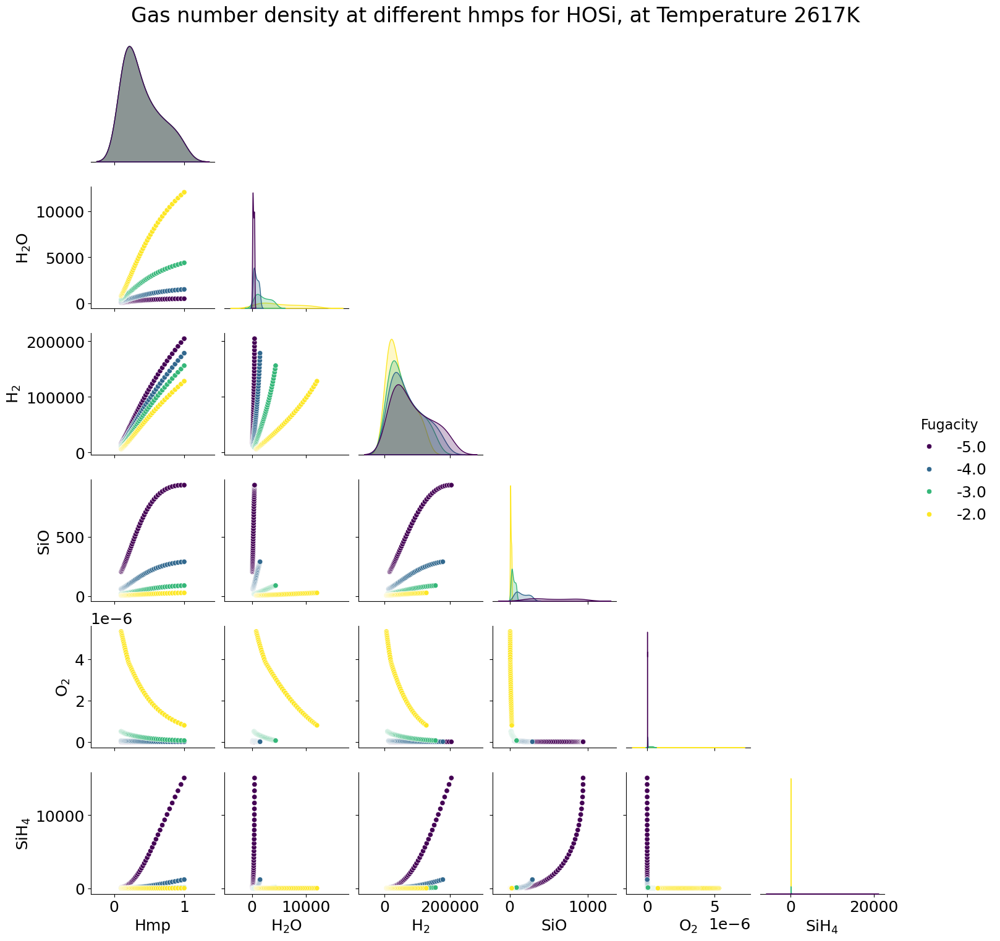

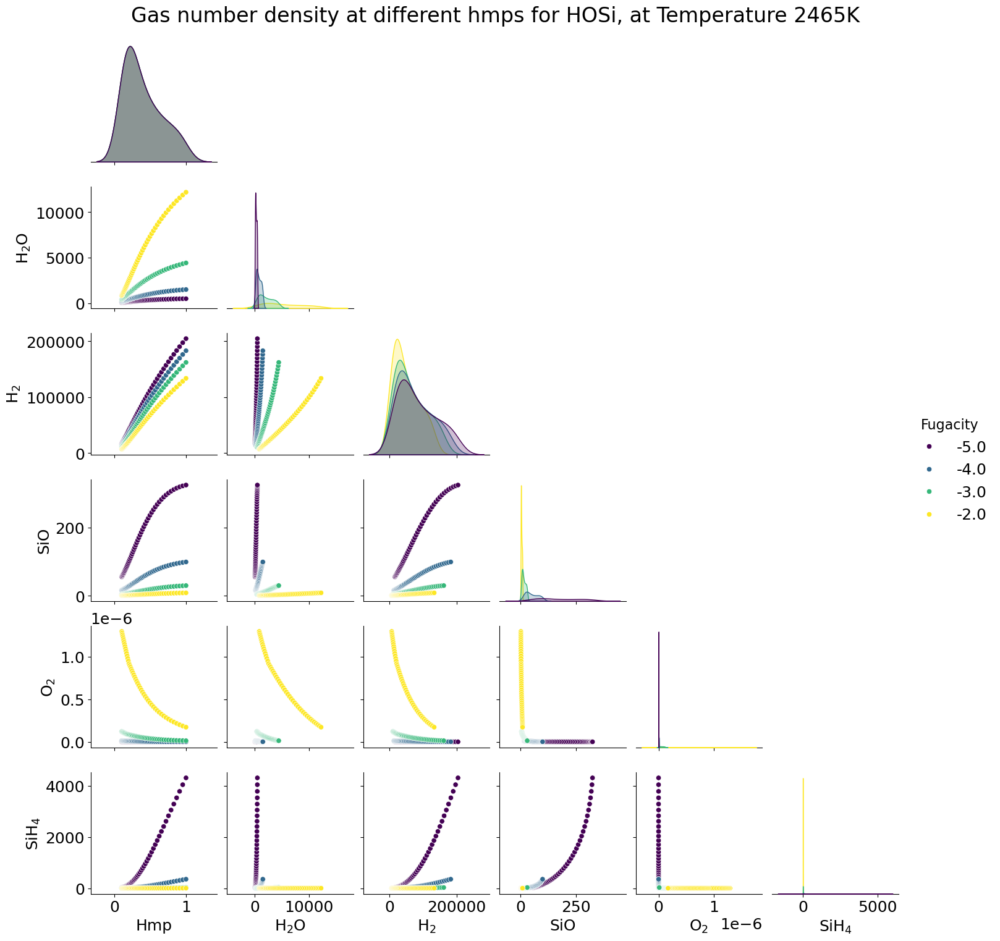

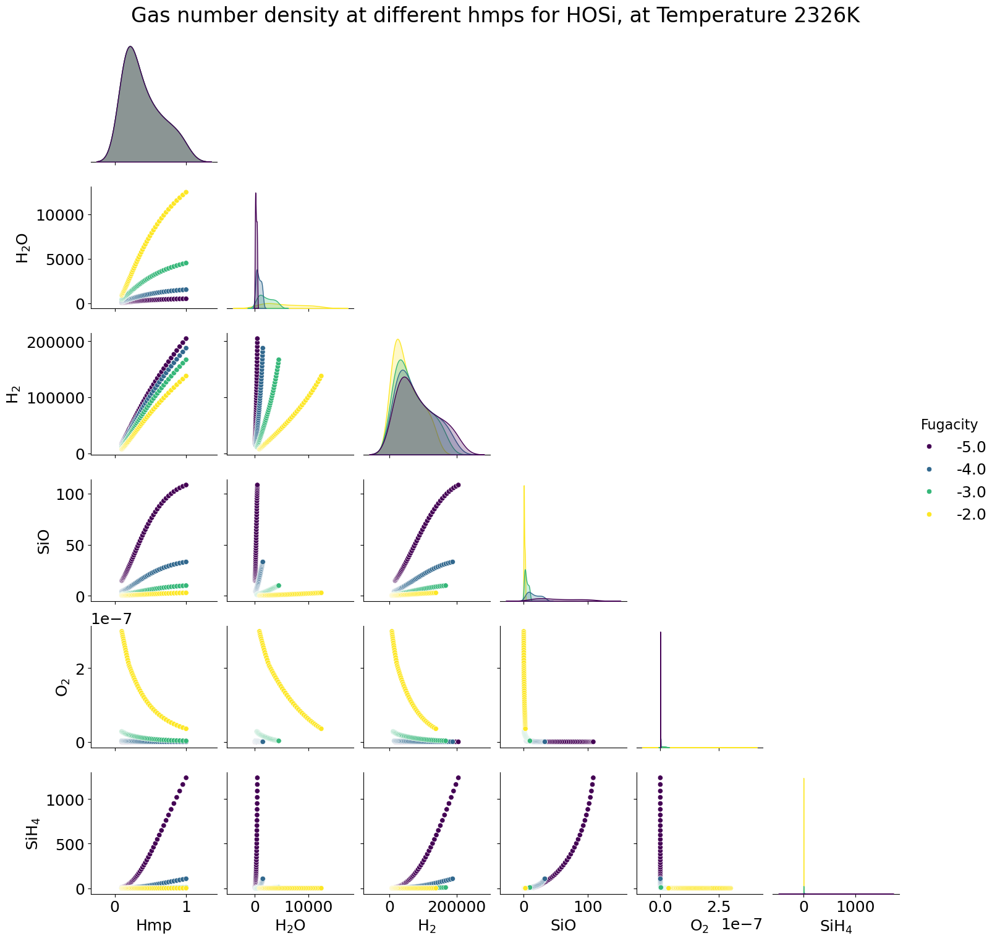

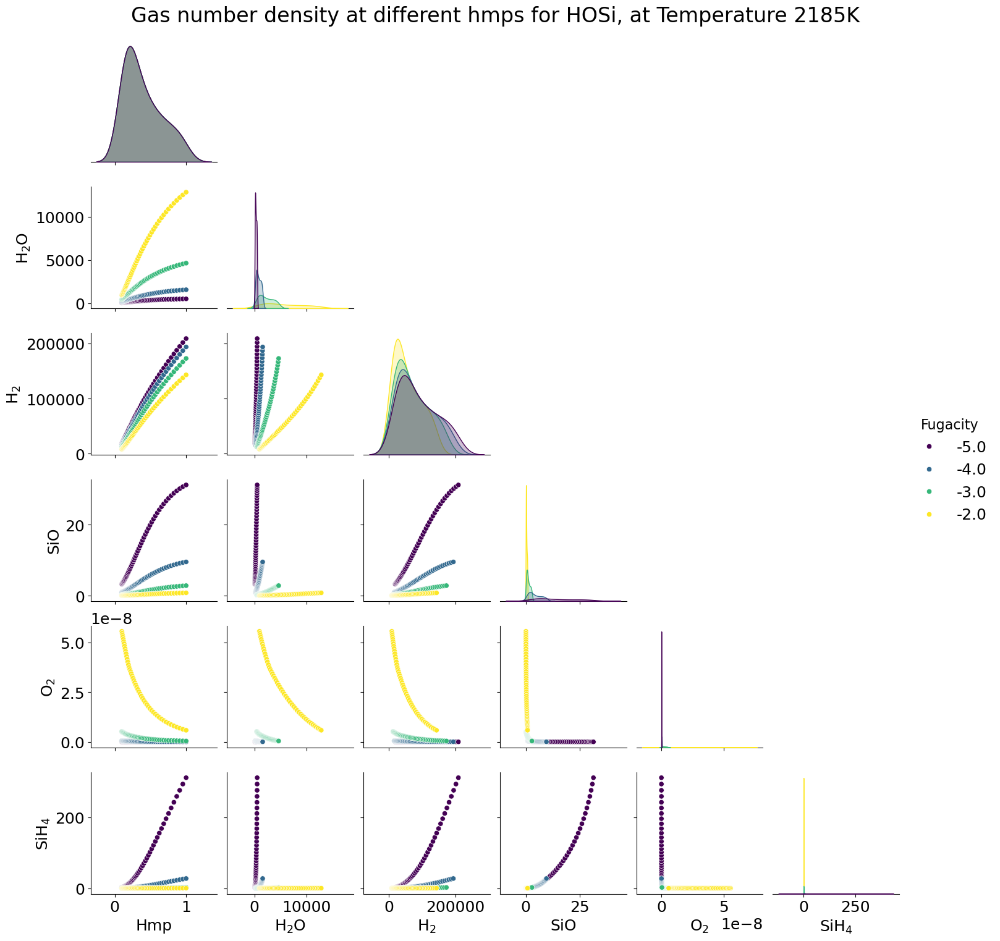

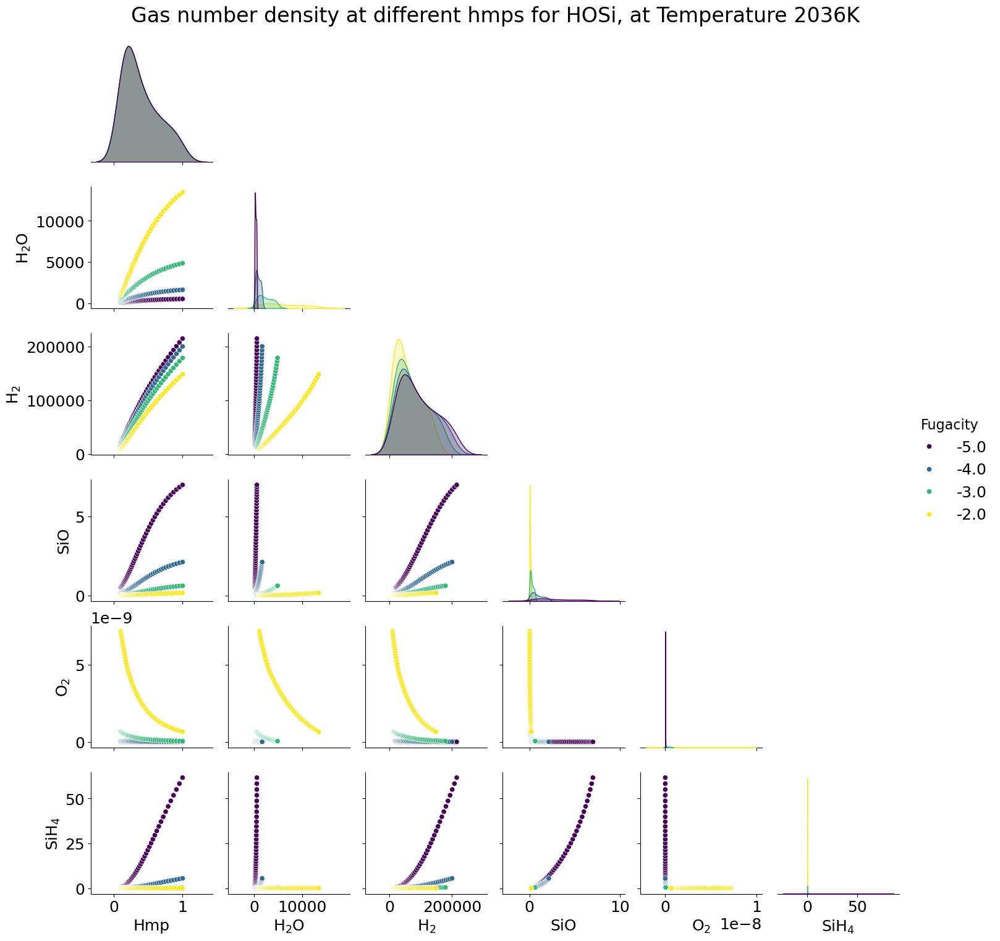

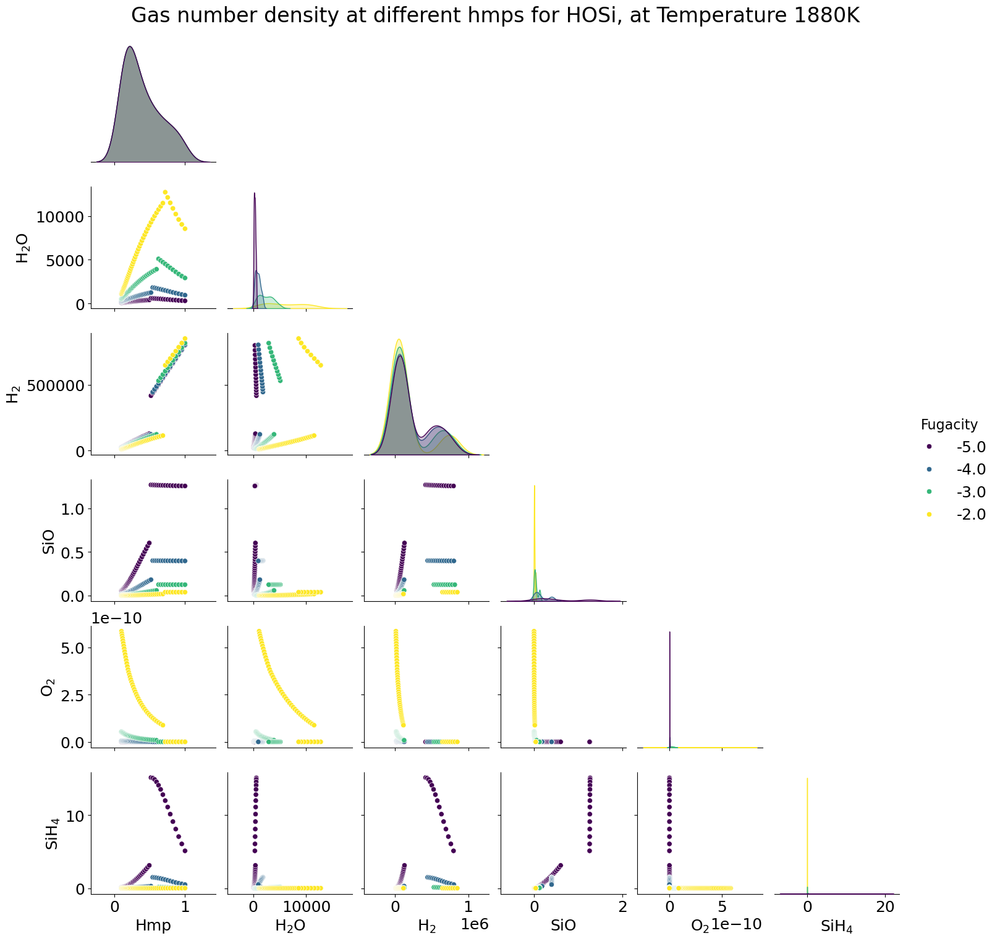

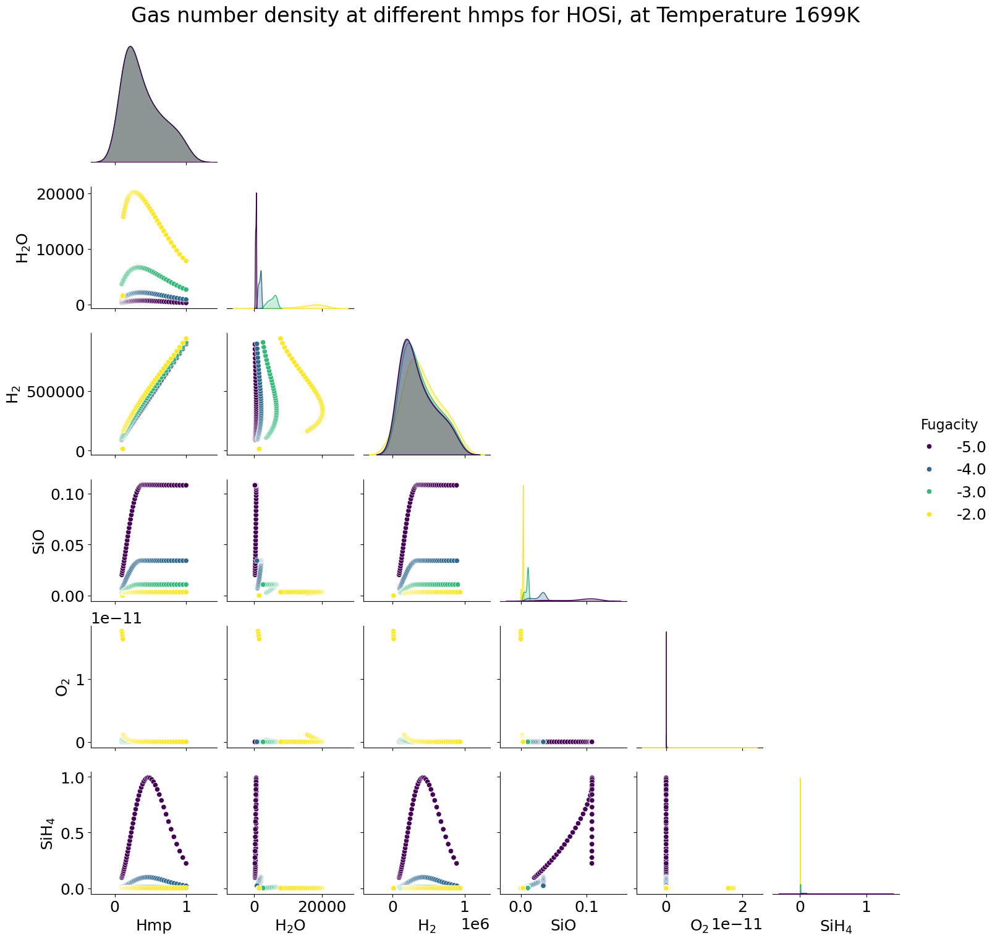

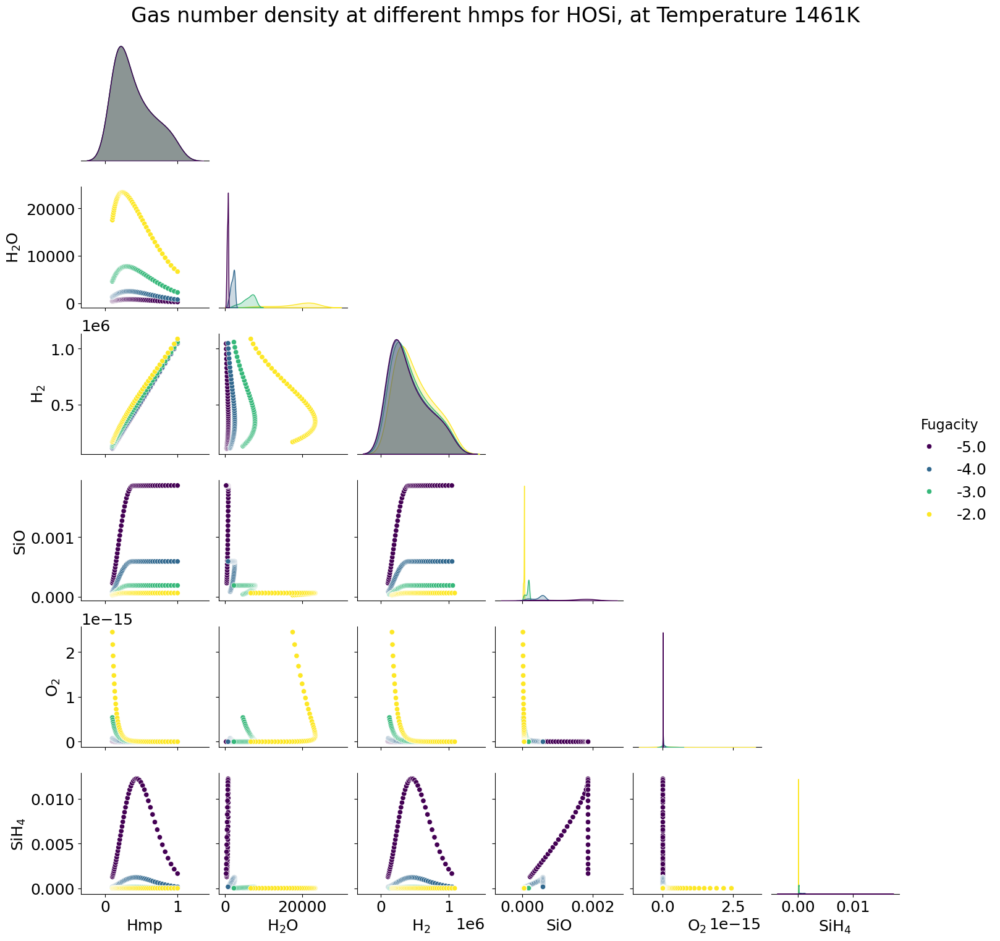

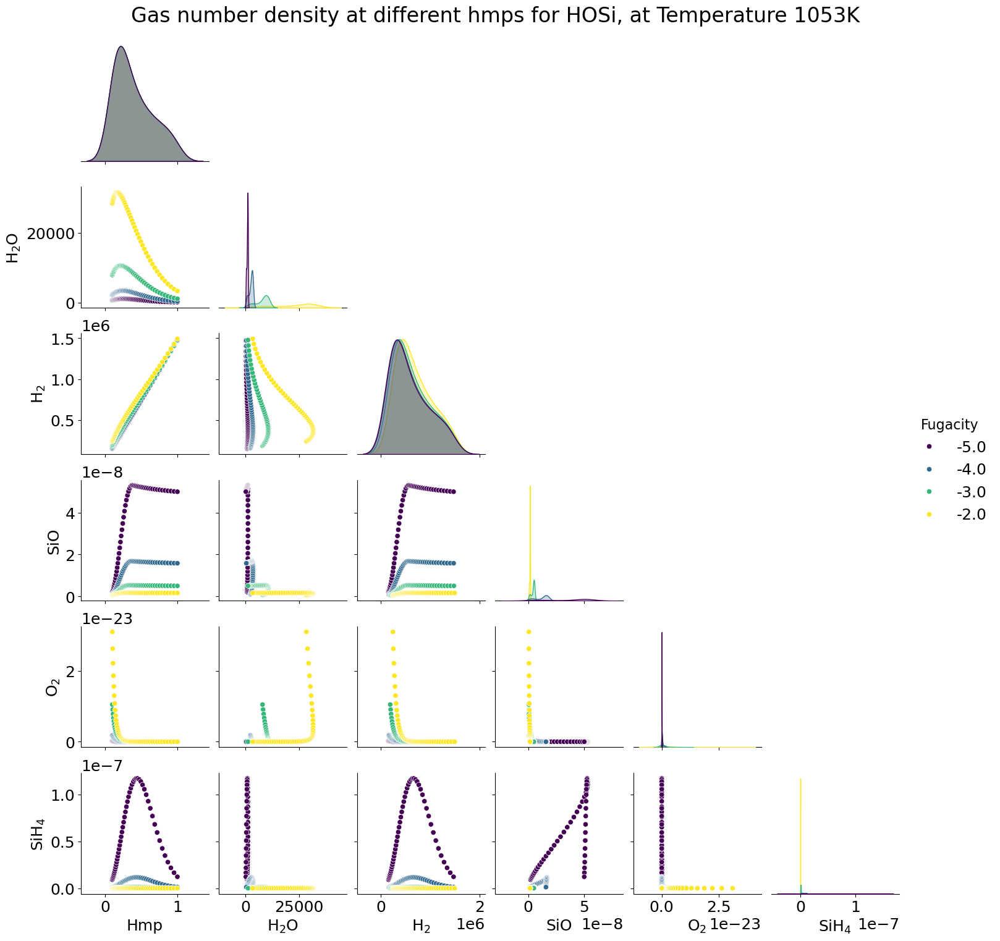

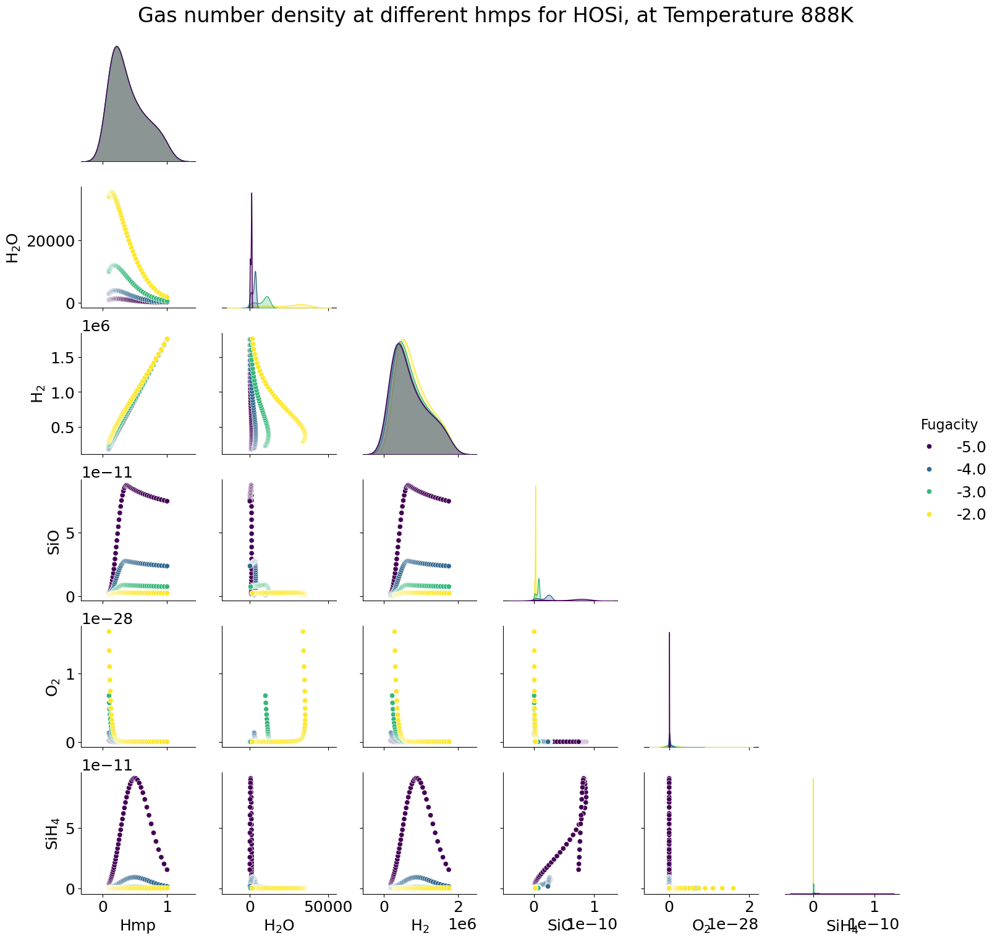

In [18]:
for temp in Temperatures_layer_time:
    df_subset = pd.DataFrame(df_gas_number_density[temp].tolist())

    g = sns.pairplot(
        df_subset,
        vars=["Hmp",r"H$_2$O", r"H$_2$", "SiO", r"O$_2$",r"SiH$_4$"],
        hue="Fugacity",
        corner=True,
        palette="viridis"
    )

    new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
    g.fig.suptitle(f"Gas number density at different hmps for HOSi, at Temperature {temp:.4g}K", y=1.02, fontsize=24)  # overall title

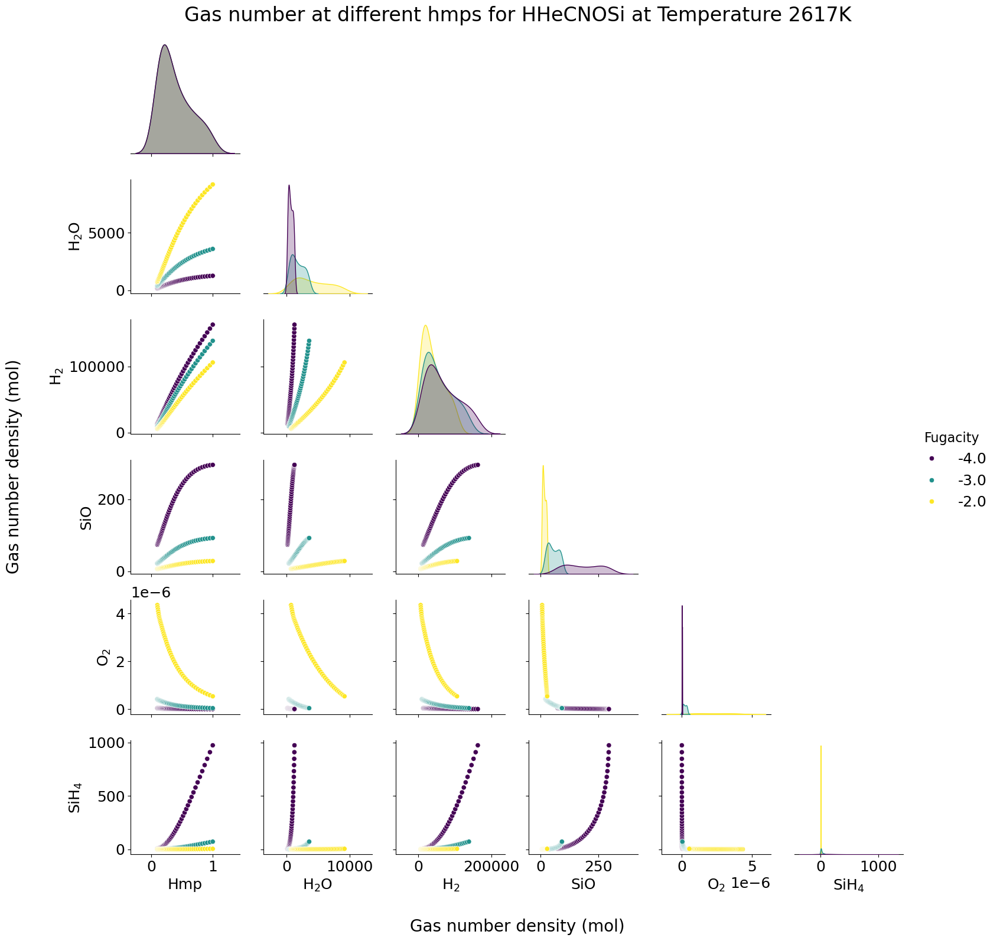

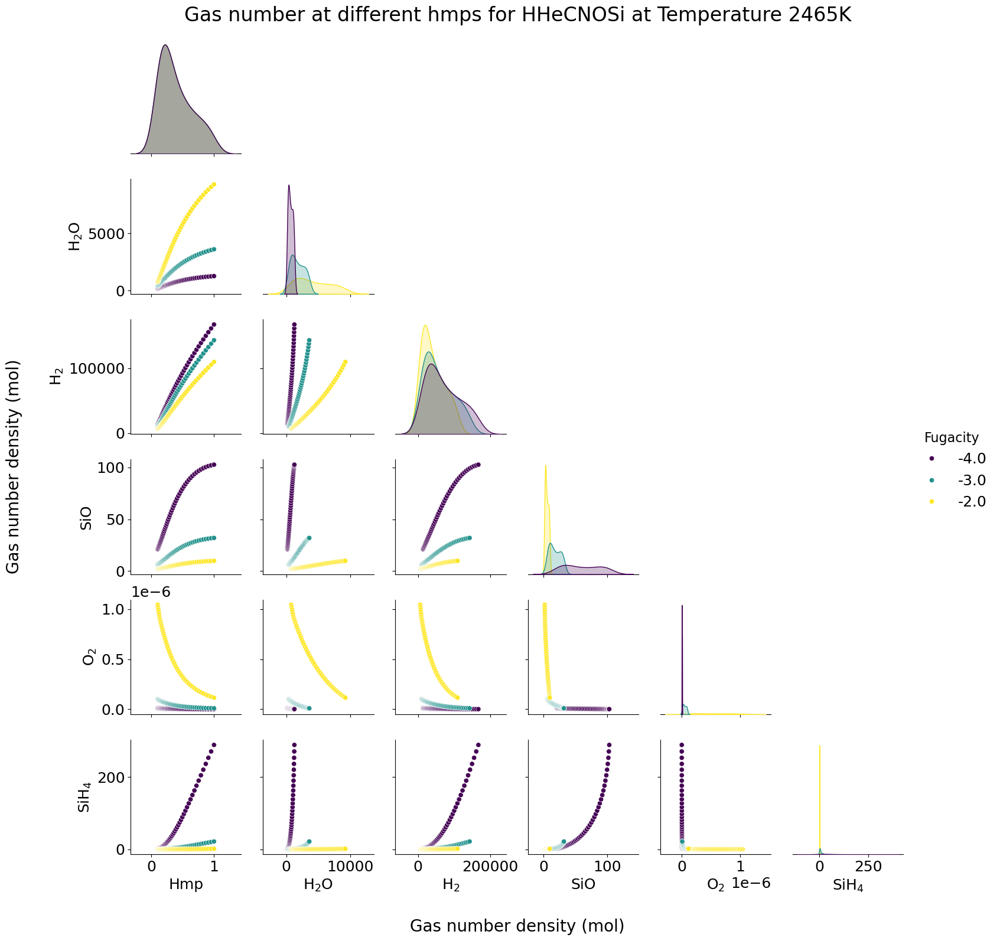

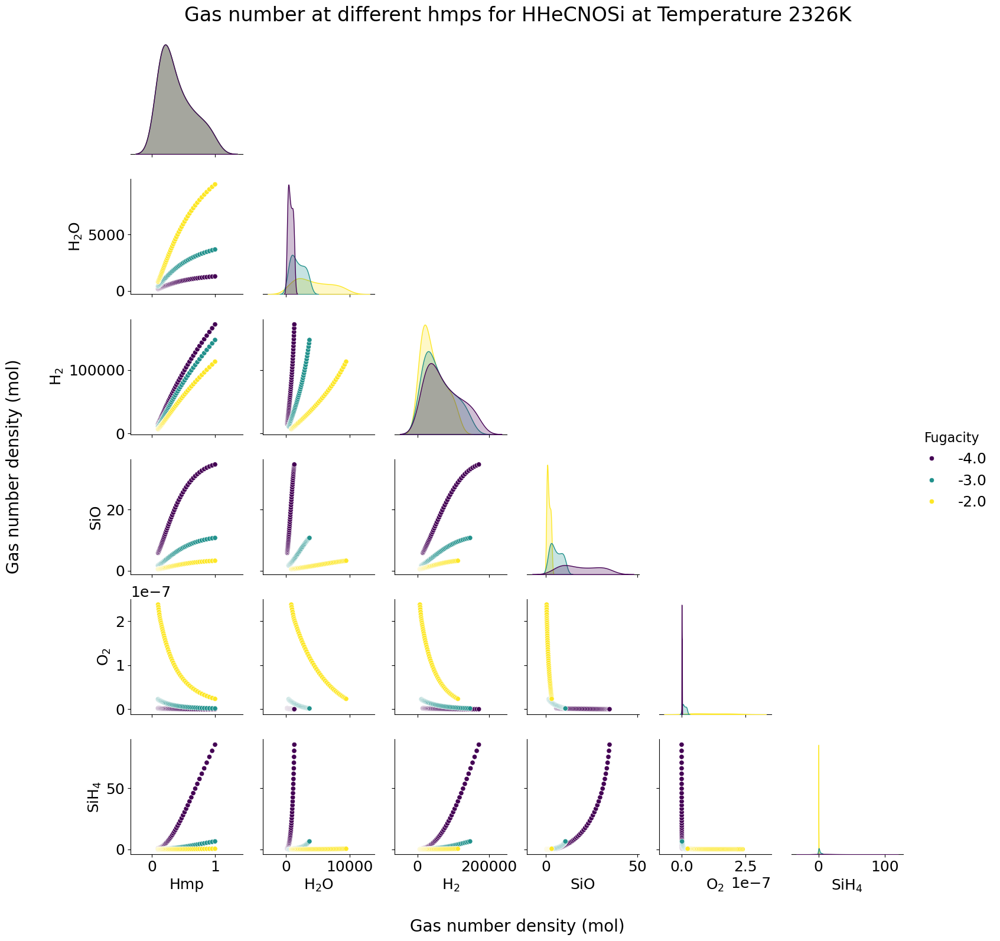

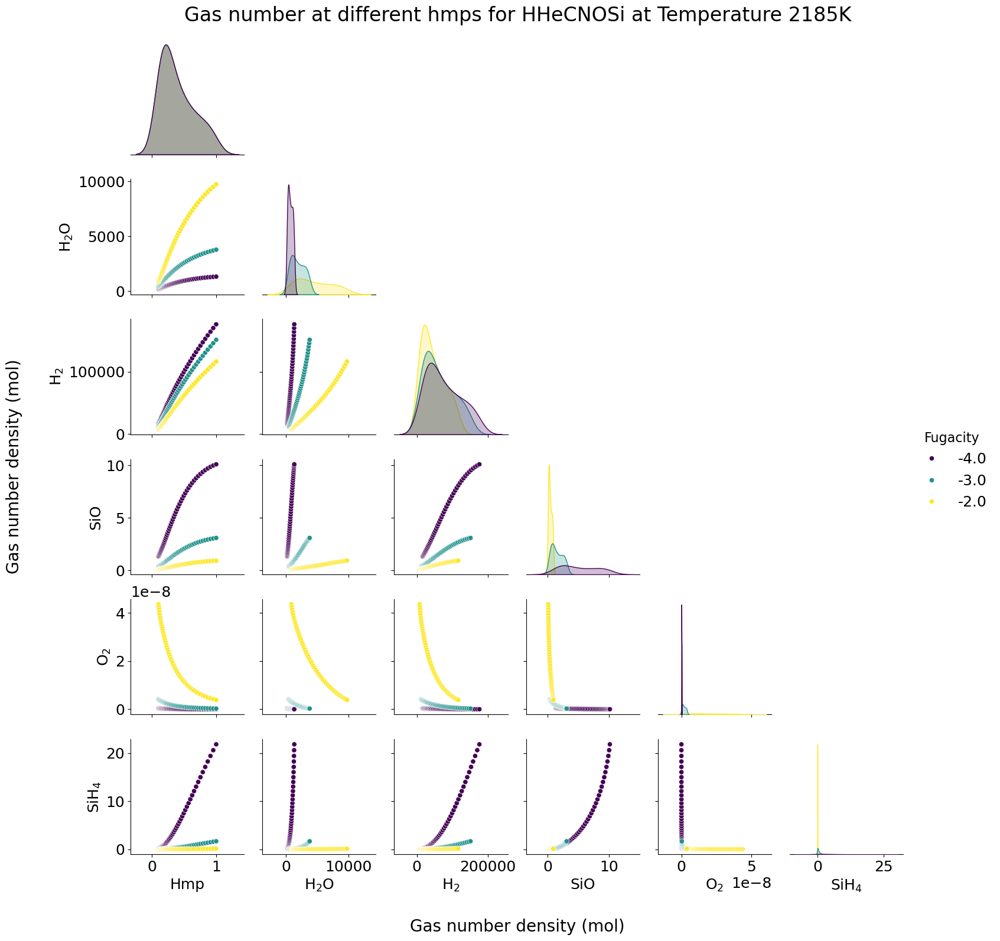

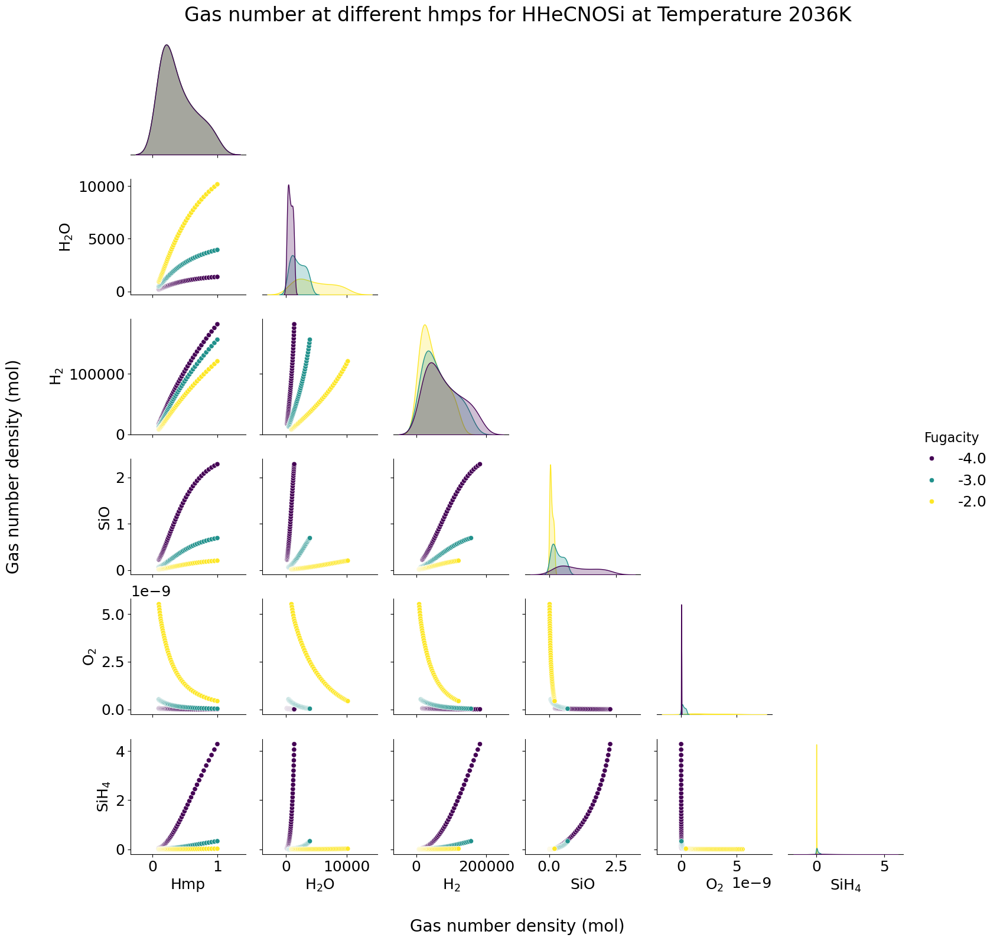

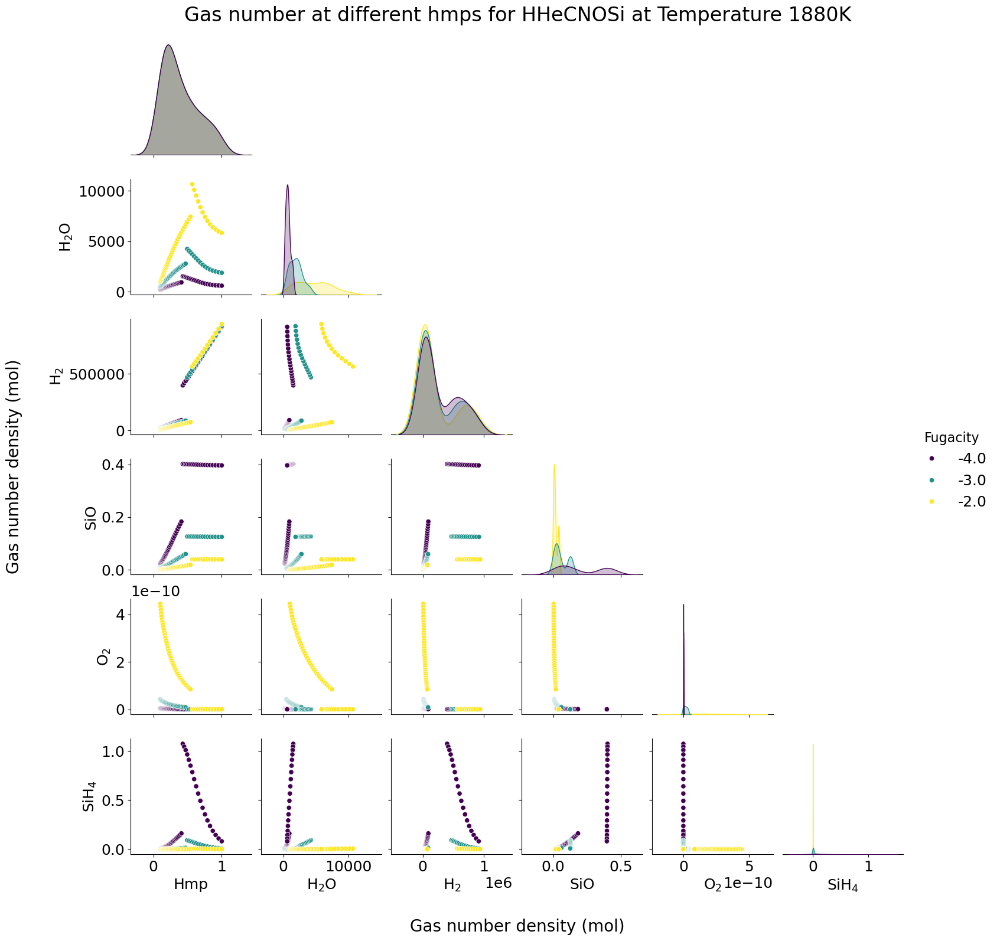

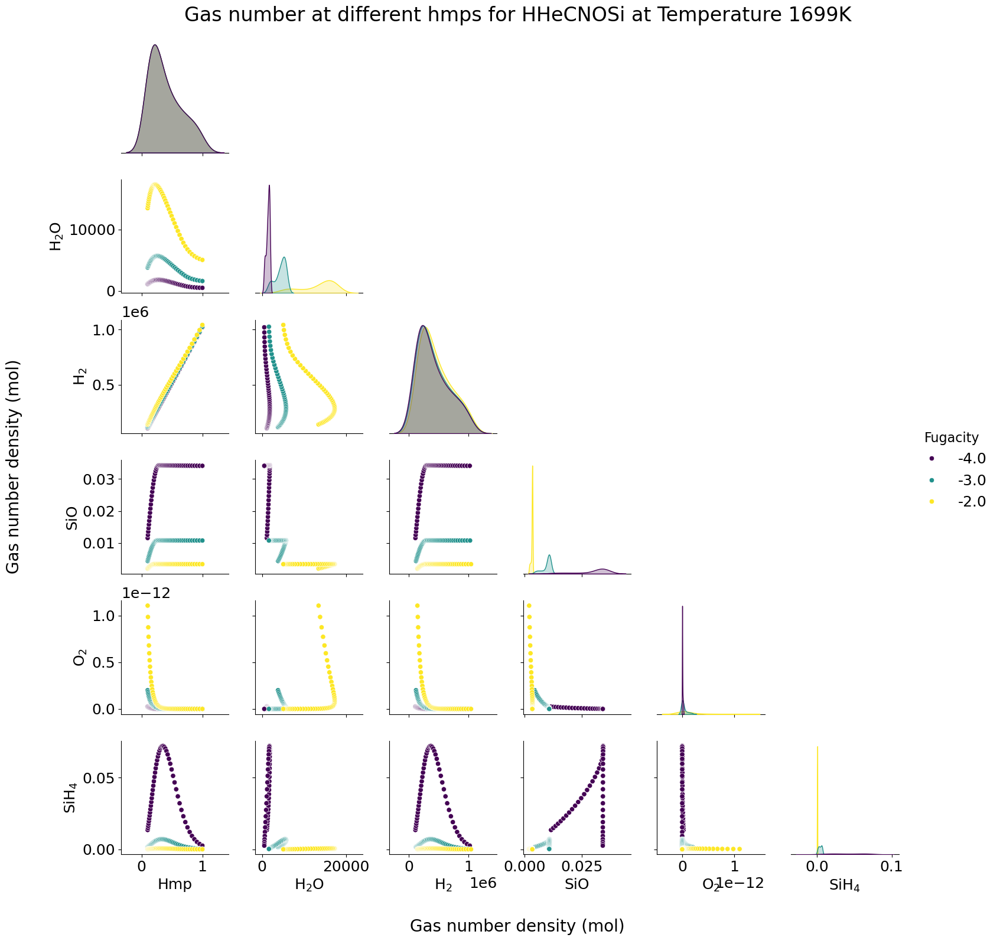

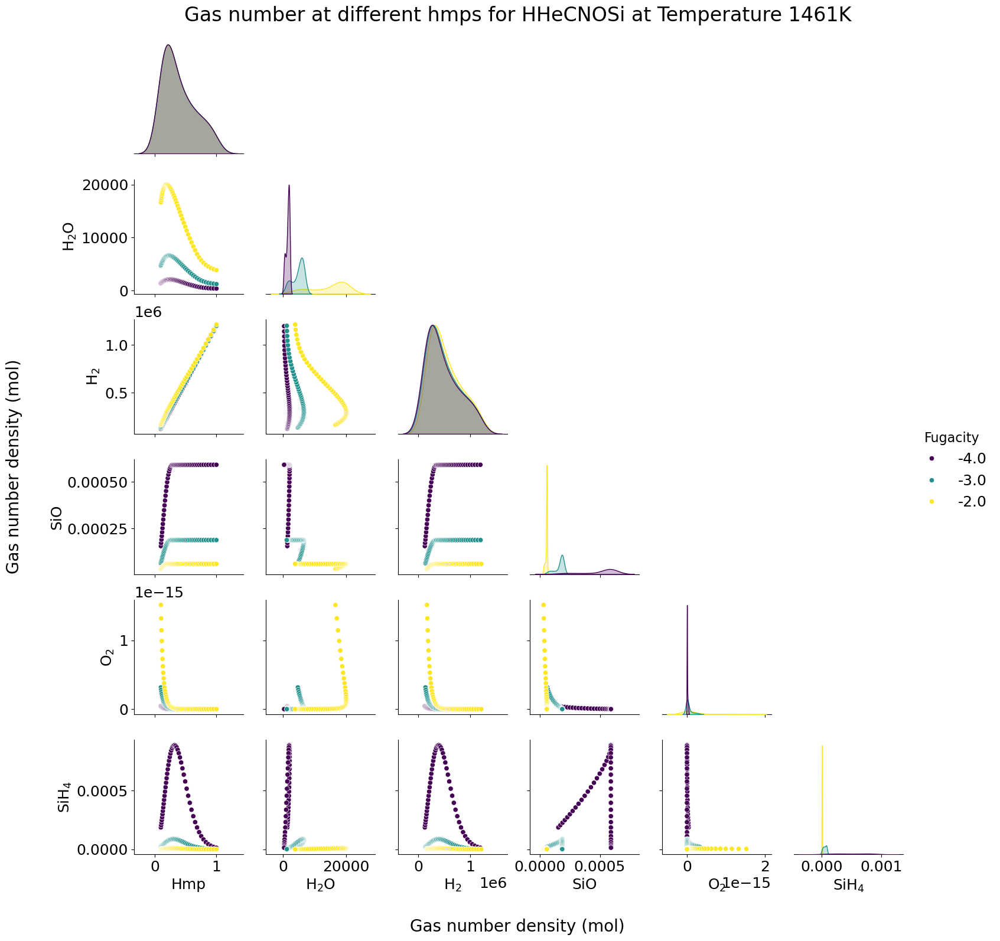

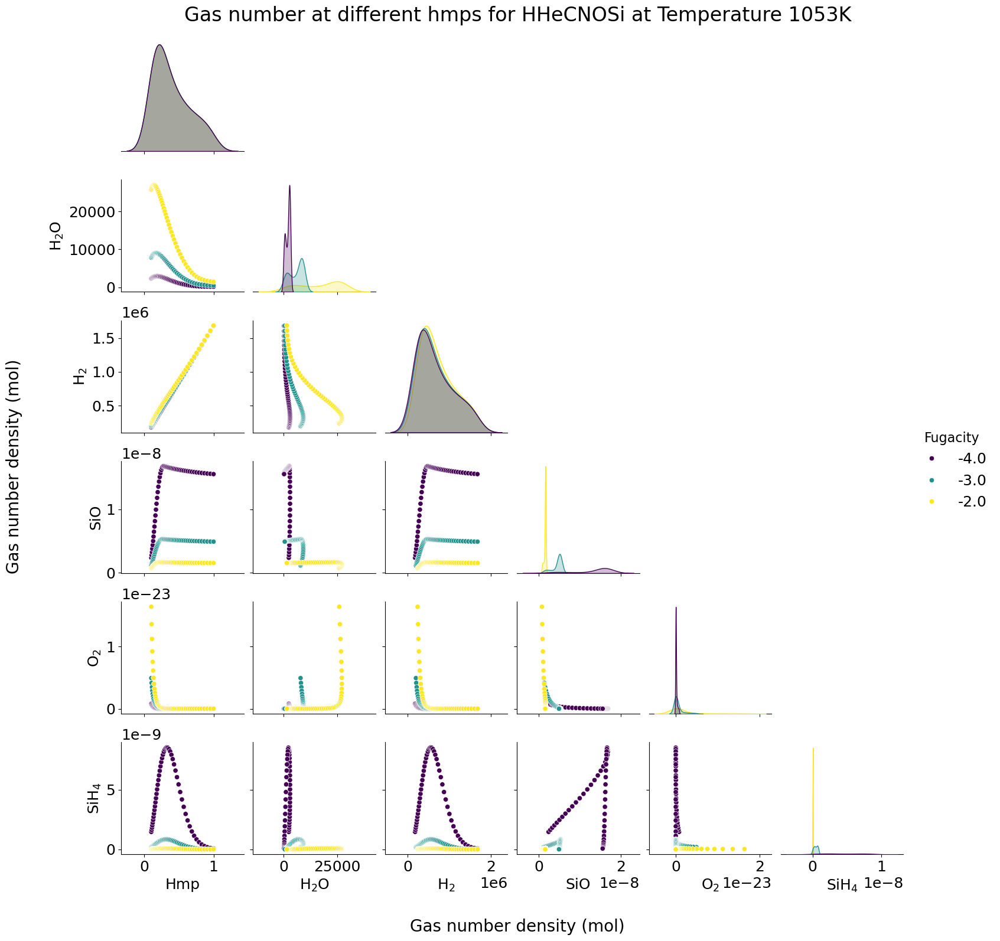

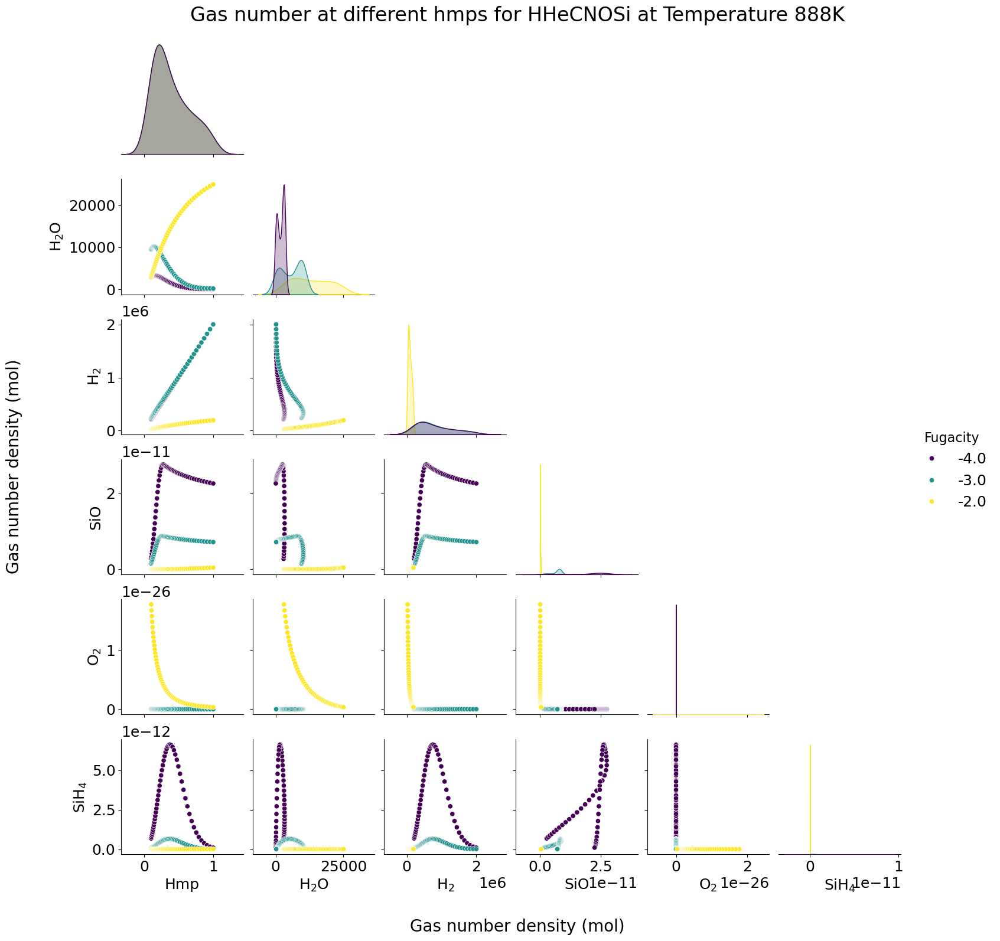

In [19]:
for temp in Temperatures_layer_time:
    df_subset = pd.DataFrame(df_gas_number_densityHHeCNOSi[temp].tolist())

    g = sns.pairplot(
        df_subset,
        vars=["Hmp",r"H$_2$O", r"H$_2$", "SiO", r"O$_2$",r"SiH$_4$"],
        hue="Fugacity",
        corner=True,
        palette="viridis"
    )

    new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
    g.fig.suptitle(f"Gas number at different hmps for HHeCNOSi at Temperature {temp:.4g}K", y=1.02, fontsize=24)  # overall title
    g.fig.text(0.5, -0.02, r"Gas number density (mol)", ha='center', va='center', fontsize=20)
    g.fig.text(-0.02, 0.5, r"Gas number density (mol)", ha='center', va='center', rotation=90, fontsize=20)

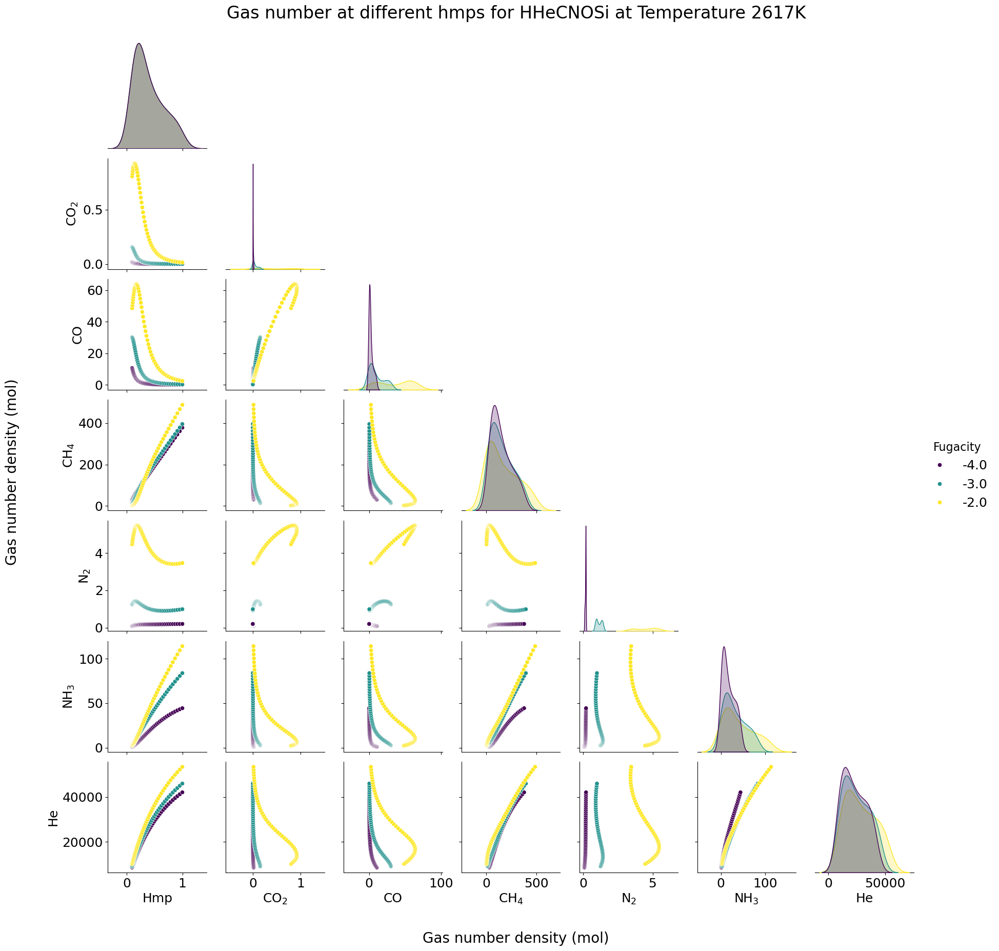

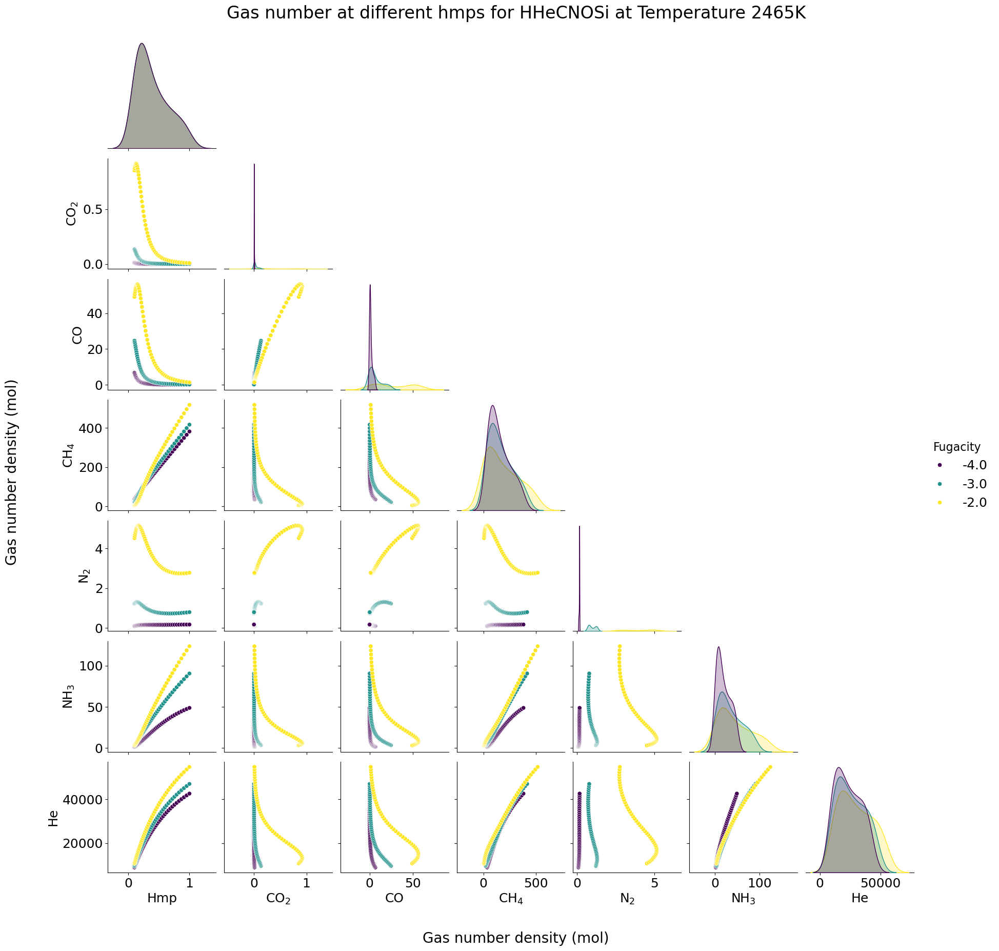

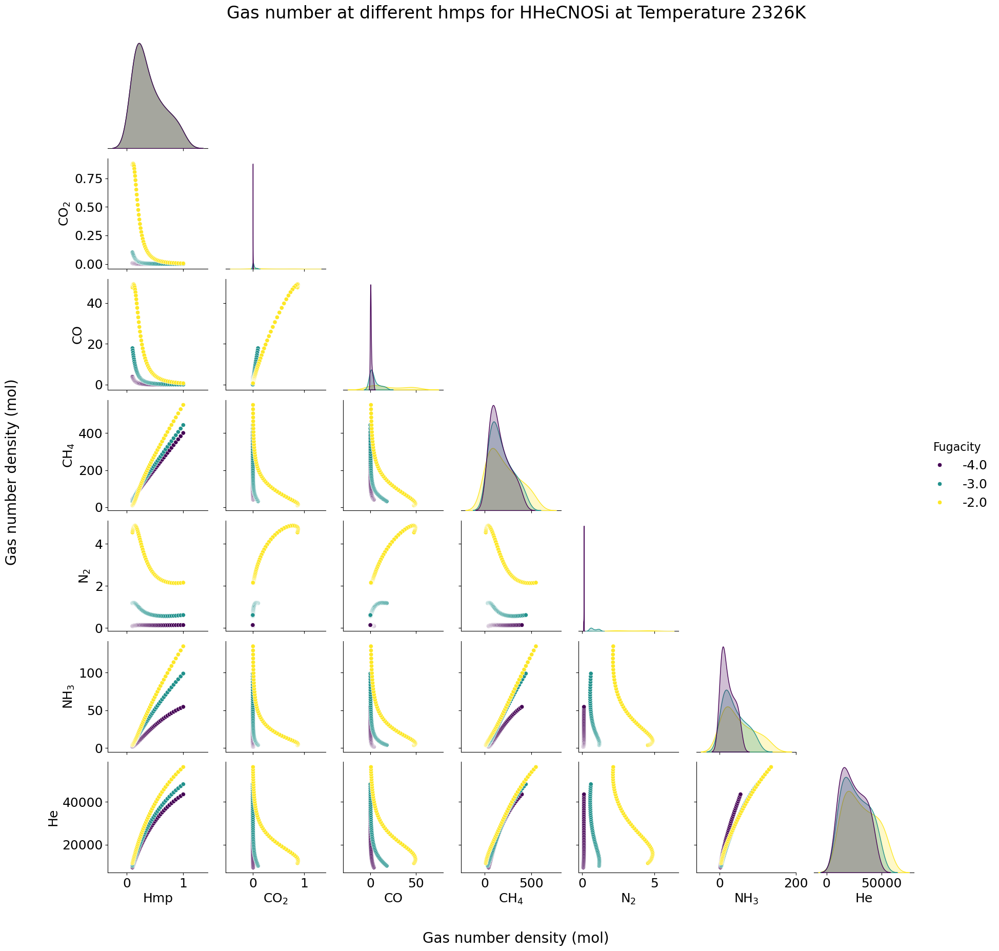

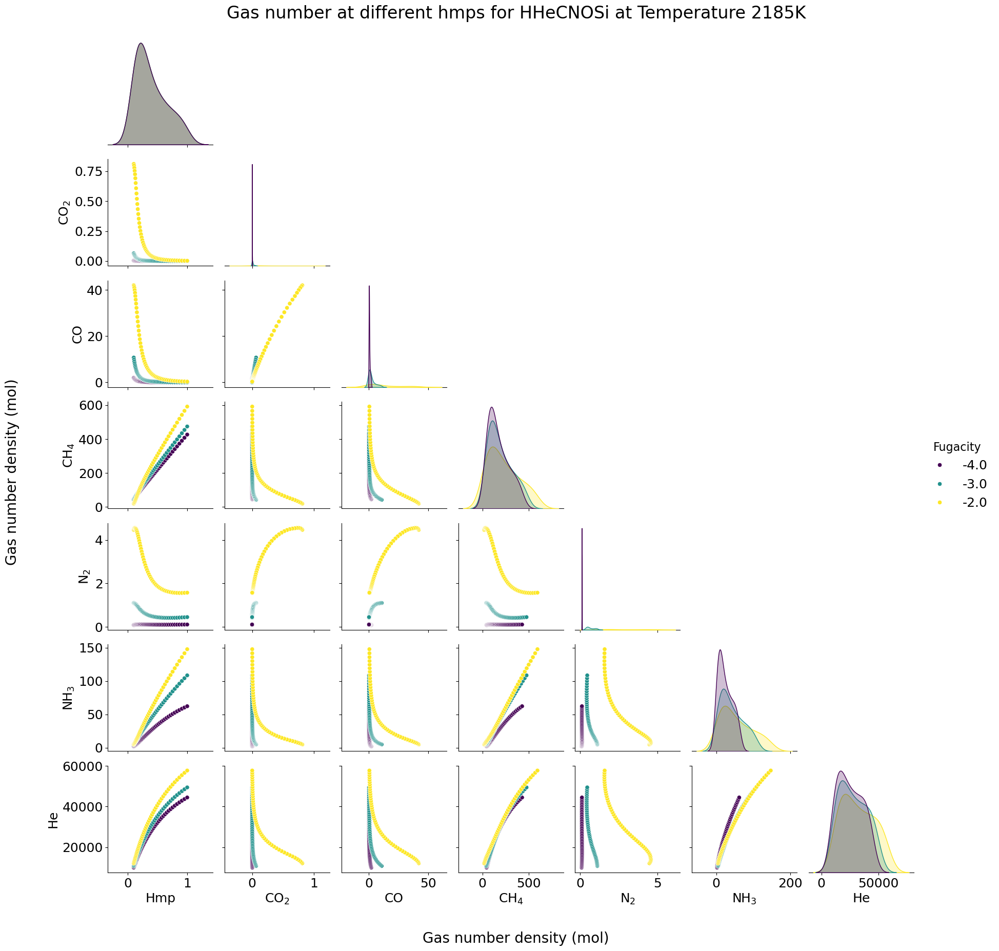

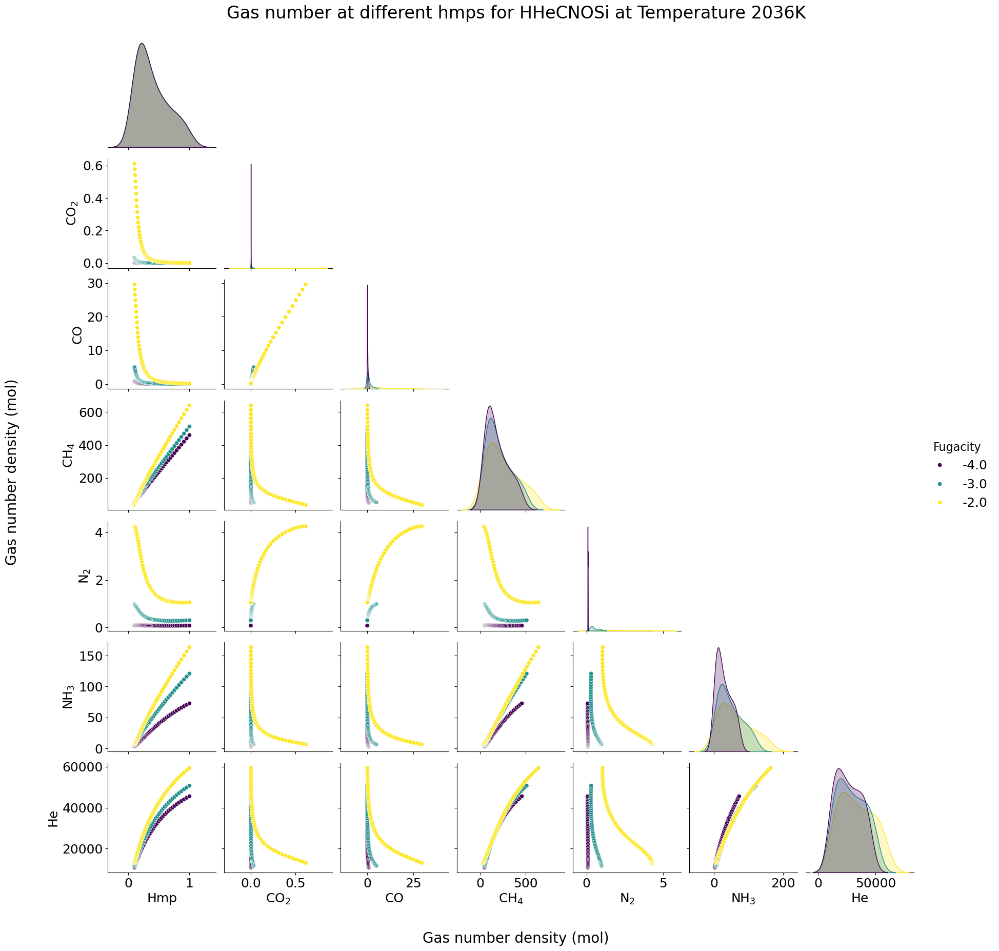

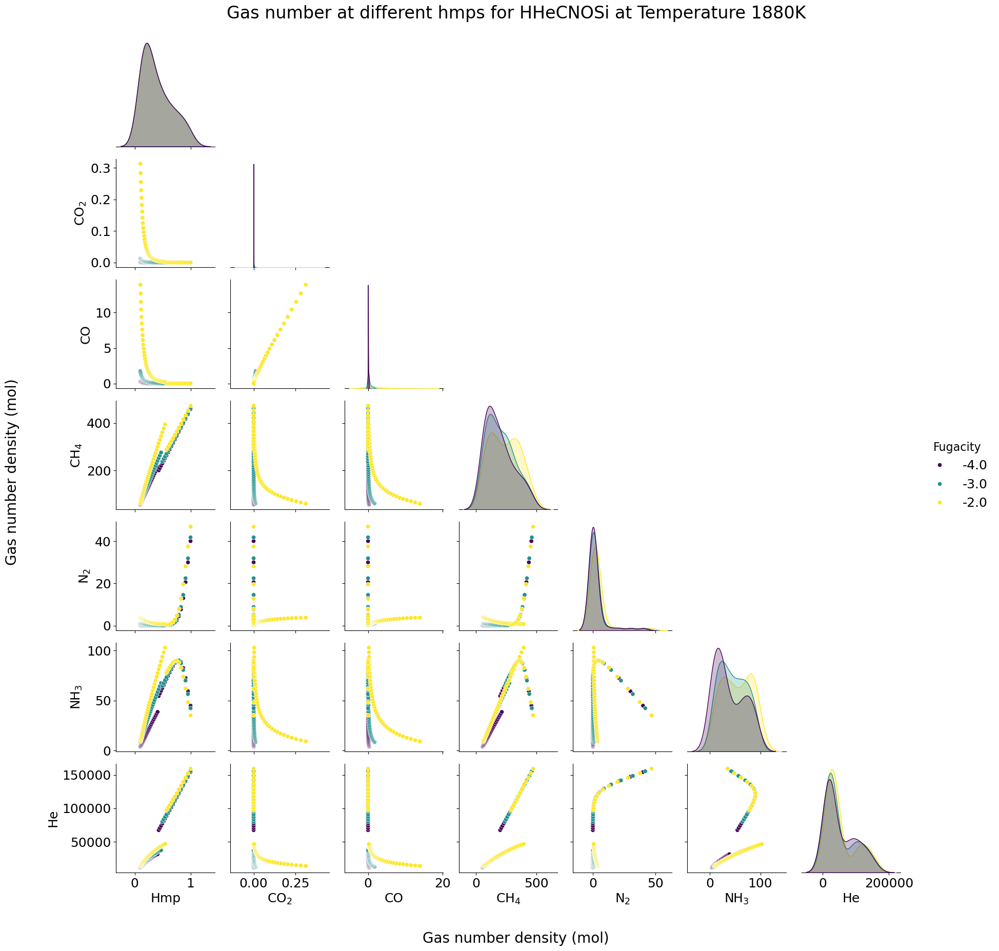

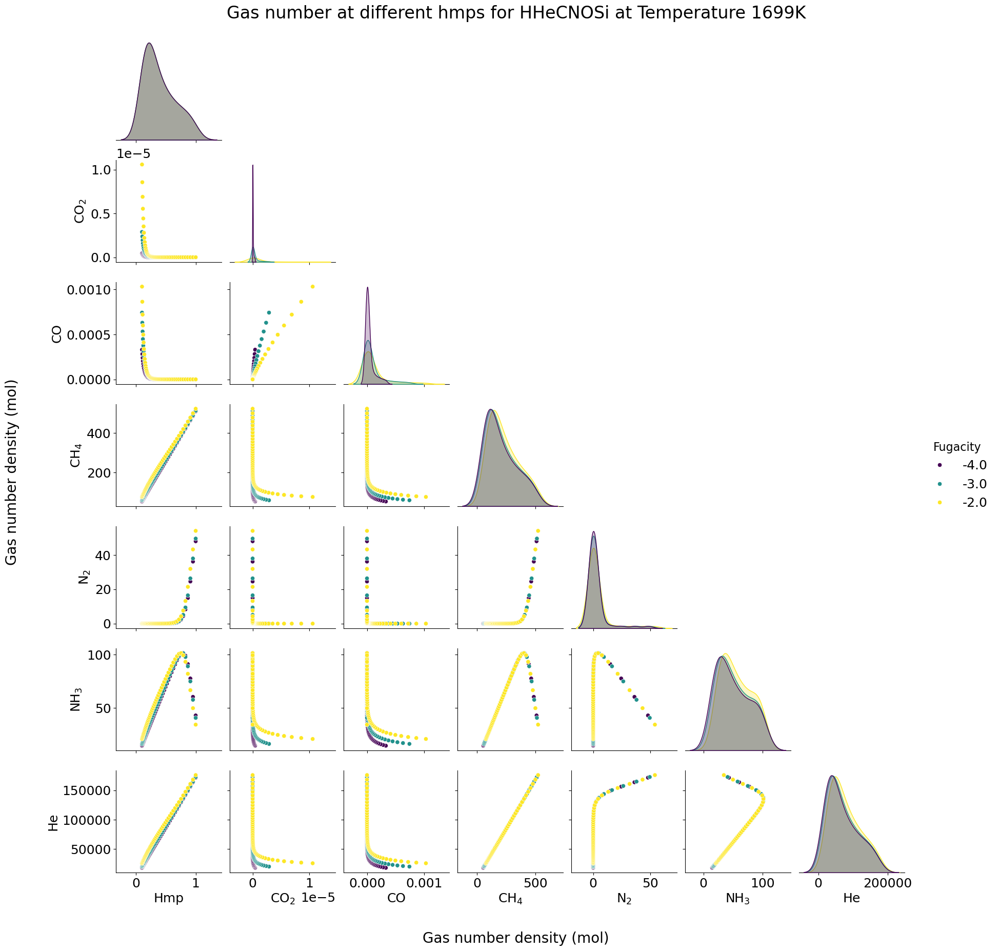

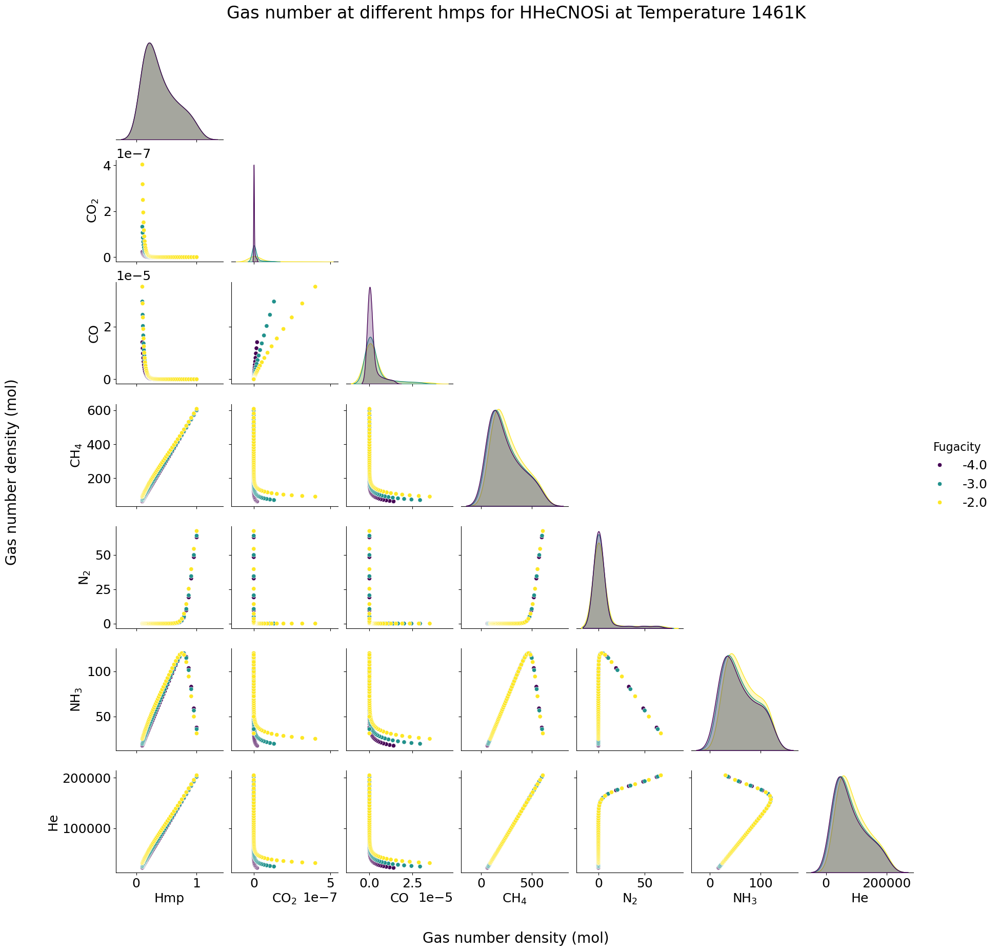

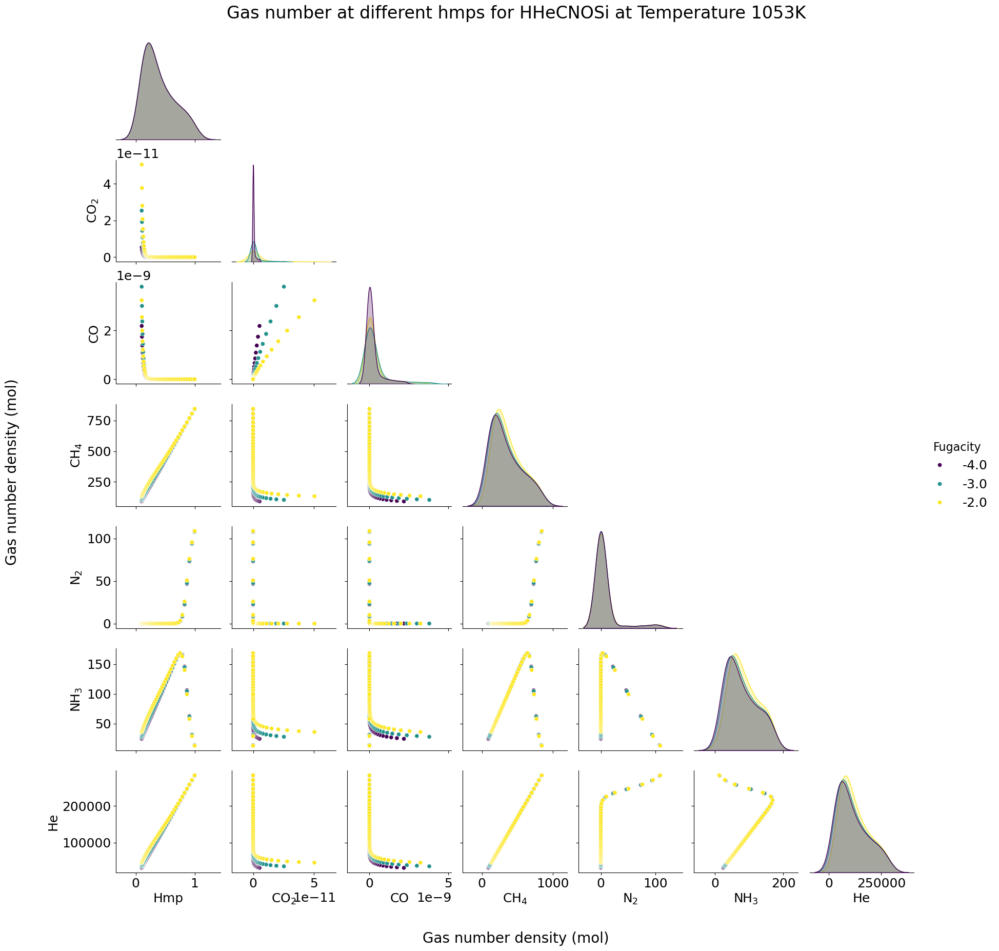

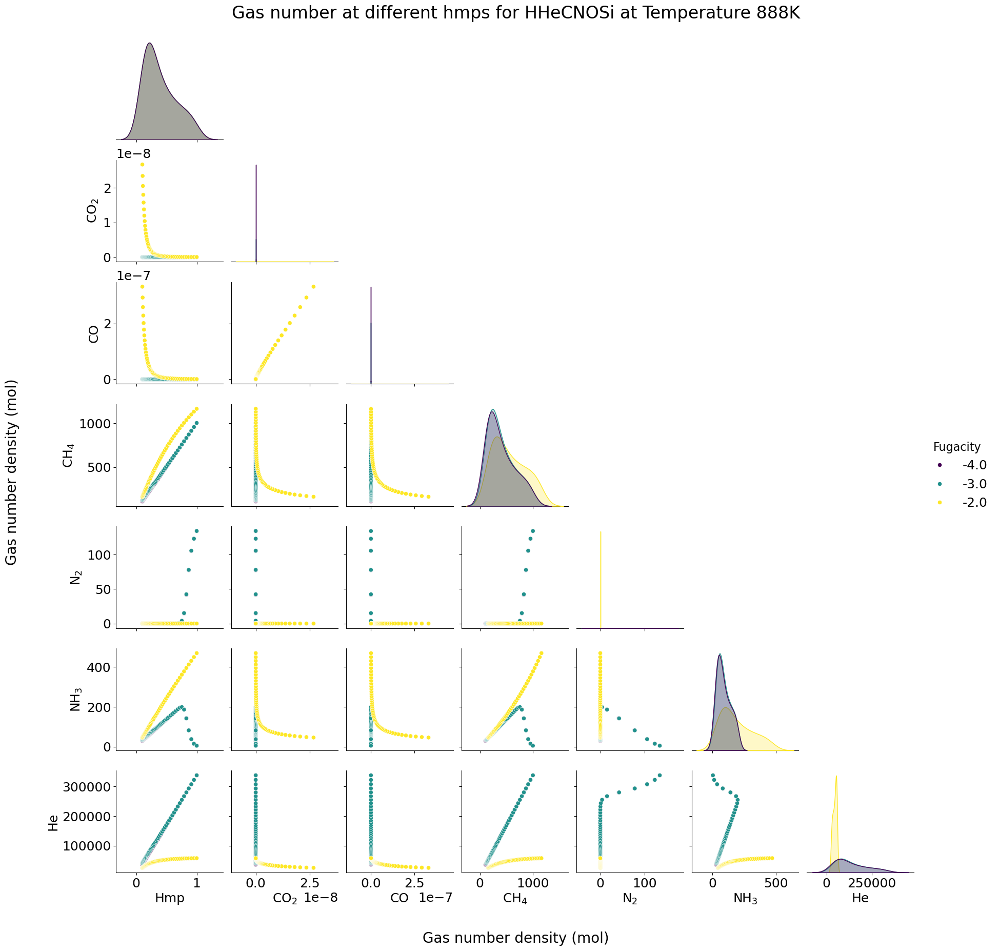

In [20]:
#use partial pressures: one or two hmps points: plot volume mixing ration in function of pressure, total pressure vertical axis -> convention! 
#use units that are of the most use in thermodynamics (partial pressure bc of experimental)


for temp in Temperatures_layer_time:
    df_subset = pd.DataFrame(df_gas_number_densityHHeCNOSi[temp].tolist())

    g = sns.pairplot(
        df_subset,
        vars=["Hmp",r"CO$_2$","CO",r"CH$_4$",r"N$_2$",r"NH$_3$","He"],
        hue="Fugacity",
        corner=True,
        palette="viridis"
    )

    new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
    g.fig.suptitle(f"Gas number at different hmps for HHeCNOSi at Temperature {temp:.4g}K", y=1.02, fontsize=24)  # overall title
    g.fig.text(0.5, -0.02, r"Gas number density (mol)", ha='center', va='center', fontsize=20)
    g.fig.text(-0.02, 0.5, r"Gas number density (mol)", ha='center', va='center', rotation=90, fontsize=20)

In [ ]:
# Normalizing
def normalize_dict(comp_dict):
    total = sum(comp_dict.values())
    return {k: (v/total)*100 for k, v in comp_dict.items()}

fO2_log10_shifts = [-4,-3,-2]
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    fig, axes = plt.subplots(3, 3, figsize=(12, 10))
    mantle_melt_fractions = [1]
    init_metallicitys = [1]
    init_metallicity = 1
    for i, ax in enumerate(axes.flat):
        filename = f"./excel_Uranus_time/HHeCNOSi/rho{rho_centre}/core_boundary/HHeCNOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_T{Temperatures_layer_time.iloc[i]:.4g}K.xlsx"
        H2O_atmosphere_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
        H2_atmosphere_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
        O2_atmosphere_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
        SiO_atmosphere_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
        SiH4_atmosphere_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
        He_atmosphere_mass = pd.read_excel(filename, sheet_name="He_g")["gas_mass"]
        CO2_atmosphere_mass = pd.read_excel(filename, sheet_name="CO2_g")["gas_mass"]
        CO_atmosphere_mass = pd.read_excel(filename, sheet_name="CO_g")["gas_mass"]
        CH4_atmosphere_mass = pd.read_excel(filename, sheet_name="CH4_g")["gas_mass"]
        N2_atmosphere_mass = pd.read_excel(filename, sheet_name="N2_g")["gas_mass"]
        NH3_atmosphere_mass = pd.read_excel(filename, sheet_name="H3N_g")["gas_mass"]
        tot_atmosphere_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"] - pd.read_excel(filename, sheet_name="state")["mantle_mass"]

        H2O_mantle_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
        H2_mantle_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
        O2_mantle_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
        SiO_mantle_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
        SiH4_mantle_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
        He_mantle_mass = pd.read_excel(filename, sheet_name="He_g")["dissolved_mass"]
        CO2_mantle_mass = pd.read_excel(filename, sheet_name="CO2_g")["dissolved_mass"]
        CO_mantle_mass = pd.read_excel(filename, sheet_name="CO_g")["dissolved_mass"]
        CH4_mantle_mass = pd.read_excel(filename, sheet_name="CH4_g")["dissolved_mass"]
        N2_mantle_mass = pd.read_excel(filename, sheet_name="N2_g")["dissolved_mass"]
        NH3_mantle_mass = pd.read_excel(filename, sheet_name="H3N_g")["dissolved_mass"]
        SiO2_mantle_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
        tot_mantle_mass = pd.read_excel(filename, sheet_name="state")["mantle_mass"]

        H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
        H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
        O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
        SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
        SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
        He_mass = pd.read_excel(filename, sheet_name="He_g")["total_mass"]
        CO2_mass = pd.read_excel(filename, sheet_name="CO2_g")["total_mass"]
        CO_mass = pd.read_excel(filename, sheet_name="CO_g")["total_mass"]
        CH4_mass = pd.read_excel(filename, sheet_name="CH4_g")["total_mass"]
        N2_mass = pd.read_excel(filename, sheet_name="N2_g")["total_mass"]
        NH3_mass = pd.read_excel(filename, sheet_name="H3N_g")["total_mass"]
        SiO2_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]

        tot_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"]

        H2O_envelope_perc = H2O_atmosphere_mass/tot_atmosphere_mass
        H2_envelope_perc = H2_atmosphere_mass/tot_atmosphere_mass
        O2_envelope_perc = O2_atmosphere_mass/tot_atmosphere_mass
        SiO_envelope_perc = SiO_atmosphere_mass/tot_atmosphere_mass
        SiH4_envelope_perc = SiH4_atmosphere_mass/tot_atmosphere_mass
        He_envelope_perc = He_atmosphere_mass/tot_atmosphere_mass
        CO2_envelope_perc = CO2_atmosphere_mass/tot_atmosphere_mass
        CO_envelope_perc = CO_atmosphere_mass/tot_atmosphere_mass
        CH4_envelope_perc = CH4_atmosphere_mass/tot_atmosphere_mass
        N2_envelope_perc = N2_atmosphere_mass/tot_atmosphere_mass
        NH3_envelope_perc = NH3_atmosphere_mass/tot_atmosphere_mass

        H2O_mantle_perc = H2O_mantle_mass/tot_mantle_mass
        H2_mantle_perc = H2_mantle_mass/tot_mantle_mass
        O2_mantle_perc = O2_mantle_mass/tot_mantle_mass
        SiO_mantle_perc = SiO_mantle_mass/tot_mantle_mass
        SiH4_mantle_perc = SiH4_mantle_mass/tot_mantle_mass
        He_mantle_perc = He_mantle_mass/tot_mantle_mass
        CO2_mantle_perc = CO2_mantle_mass/tot_mantle_mass
        CO_mantle_perc = CO_mantle_mass/tot_mantle_mass
        CH4_mantle_perc = CH4_mantle_mass/tot_mantle_mass
        N2_mantle_perc = N2_mantle_mass/tot_mantle_mass
        NH3_mantle_perc = NH3_mantle_mass/tot_mantle_mass
        SiO2_mantle_perc = SiO2_mantle_mass/tot_mantle_mass


        H2O_perc = H2O_mass/tot_mass
        H2_perc = H2_mass/tot_mass
        O2_perc = O2_mass/tot_mass
        SiO_perc = SiO_mass/tot_mass
        SiH4_perc = SiH4_mass/tot_mass
        He_perc = He_mass/tot_mass
        CO2_perc = CO2_mass/tot_mass
        CO_perc = CO_mass/tot_mass
        CH4_perc = CH4_mass/tot_mass
        N2_perc = N2_mass/tot_mass
        NH3_perc = NH3_mass/tot_mass
        SiO2_perc = SiO2_mass/tot_mass


        # Core composition
        core_composition = {
            'H2O': H2O_mantle_perc[0]*100,
            'H2': H2_mantle_perc[0]*100,
            'He': He_mantle_perc[0]*100,
            'SiH4': SiH4_mantle_perc[0]*100,   # adjust these to sum to 100
            'SiO': SiO_mantle_perc[0]*100,
            'SiO2': SiO2_mantle_perc[0]*100,
            'O2': O2_mantle_perc[0]*100,
            'CO2': CO2_mantle_perc[0]*100,
            'CO': CO_mantle_perc[0]*100,
            'CH4': CH4_mantle_perc[0]*100,
            'N2': N2_mantle_perc[0]*100,
            'NH3' : NH3_mantle_perc[0]*100
        }

        # Envelope composition
        envelope_composition = {
            'H2O': H2O_envelope_perc[0]*100,
            'H2': H2_envelope_perc[0]*100,
            'He': He_envelope_perc[0]*100,
            'SiH4': SiH4_envelope_perc[0]*100,   # adjust these to sum to 100
            'SiO': SiO_envelope_perc[0]*100,
            'O2': O2_envelope_perc[0]*100,
            'CO2': CO2_envelope_perc[0]*100,
            'CO': CO_envelope_perc[0]*100,
            'CH4': CH4_envelope_perc[0]*100,
            'N2': N2_envelope_perc[0]*100,
            'NH3' : NH3_envelope_perc[0]*100
        }

        # Total composition
        total_composition = {
            'H2O': H2O_perc[0]*100,
            'H2': H2_perc[0]*100,
            'He': He_perc[0]*100,
            'SiH4': SiH4_perc[0]*100,   # adjust these to sum to 100
            'SiO': SiO_perc[0]*100,
            'SiO2': SiO2_perc[0]*100,
            'O2': O2_perc[0]*100,
            'CO2': CO2_perc[0]*100,
            'CO': CO_perc[0]*100,
            'CH4': CH4_perc[0]*100,
            'N2': N2_perc[0]*100,
            'NH3' : NH3_perc[0]*100
        }


        core_comp = normalize_dict(core_composition)
        env_comp = normalize_dict(envelope_composition)
        total_comp = normalize_dict(total_composition)

        # Species colors
        species_colors = {
            'SiO2': 'yellow',
            'H2O': 'blue',
            'SiH4': 'red',
            'SiO': 'brown',
            'O2': 'limegreen',
            'H2': 'orange',
            'CO2': 'cyan',
            'CO' : 'magenta',
            'He': 'gray',
            'N2': 'green',
            'CH4': 'purple',
            'NH3': 'pink',
            'MgO': 'darkred',
            'MgH2': 'gold',
            'MgH' :'teal',
            'MgOH' : 'indigo'
        
        }

        # Parameters pie chart-
        theta1, theta2 = 60, 120 # 20-degree wedge
        core_radius = Radii_time.iloc[i]/3.939  # Core extends to 0.2 R_U
        total_radius = 1.0

        # Convert composition dicts to lists
        core_species = list(core_comp.keys())
        core_percents = list(core_comp.values())
        env_species = list(env_comp.keys())
        env_percents = list(env_comp.values())

        # draw different partitions starting with core
        core_start = 0.0
        cumulative = 0.0

        for j, (species, percent) in enumerate(zip(core_species, core_percents)):
            angle_width = (theta2 - theta1) * (percent / 100)
            angle_start = theta1 + cumulative * (theta2 - theta1) / 100
            angle_end = angle_start + angle_width
    
            wedge = plt.matplotlib.patches.Wedge(
                (0, 0), core_radius,
                angle_start, angle_end,
                facecolor=species_colors.get(species, 'gray'),
                edgecolor='black',
                linewidth=0.5,
                alpha=0.8
            )
            ax.add_patch(wedge)
    
            mid_angle = (angle_start + angle_end) / 2
            label_r = core_radius / 2
            label_theta = np.radians(mid_angle)
            x = label_r * np.cos(label_theta) * 1.1
            y = label_r * np.sin(label_theta)
            cumulative += percent

        cumulative = 0.0

        for j, (species, percent) in enumerate(zip(env_species, env_percents)):
            angle_width = (theta2 - theta1) * (percent / 100)
            angle_start = theta1 + cumulative * (theta2 - theta1) / 100
            angle_end = angle_start + angle_width
    
            annulus = plt.matplotlib.patches.Wedge(
                (0, 0), total_radius,
                angle_start, angle_end,
                width=total_radius - core_radius,
                facecolor=species_colors.get(species, 'gray'),
                edgecolor='black',
                linewidth=0.5,
                alpha=0.8
            )
            ax.add_patch(annulus)
    
            mid_angle = (angle_start + angle_end) / 2
            label_r = (core_radius + total_radius) / 2
            label_theta = np.radians(mid_angle)
            x = label_r * np.cos(label_theta) * 1.1
            y = label_r * np.sin(label_theta)
            cumulative += percent

        theta_line = np.linspace(np.radians(theta1), np.radians(theta2), 100)
        x_core = core_radius * np.cos(theta_line)
        y_core = core_radius * np.sin(theta_line)
        ax.plot(x_core, y_core, 'k-', linewidth=2)

        x_outer = total_radius * np.cos(theta_line)
        y_outer = total_radius * np.sin(theta_line)
        ax.plot(x_outer, y_outer, 'k-', linewidth=2)

        legend_entries = []

        # Species that appear in one
        for species in set(core_species) or set(env_species):
            core_p = core_comp.get(species, 0)
            env_p = env_comp.get(species, 0)
            tot_p = total_comp.get(species, 0)
            if core_p > 0 or env_p > 0:
                legend_entries.append(
                    (species_colors[species], 
                     f"{species}:{env_p:.1f}% (Env)")
                )

        # Create legend patches
        legend_patches = [
            Patch(color=color, label=label, alpha=0.8)
            for color, label in legend_entries
        ]

        # Add legend
        ax.legend(handles=legend_patches, 
                  loc='upper left', 
                  bbox_to_anchor=(0.74, 1),
                  title=f"Species Composition\n(Color | % by mass) \n at Temparature layer {Temperatures_layer_time.iloc[i]:.4g}K \n fO2 = {shift}",
                  fontsize=9,
                  title_fontsize=10,
                  framealpha=0.9)

        # --- FINISH PLOT ---
        ax.set_xlim(-1.1, 1.1)  # Extra space for legend
        ax.set_ylim(-0.1, 1.1)
        ax.set_aspect('equal')
        ax.axis('off')
    plt.subplots_adjust(wspace=0.8, hspace=0.4)
    plt.subplots_adjust(right=0.75, wspace=0.8, hspace=0.4)
    plt.show()

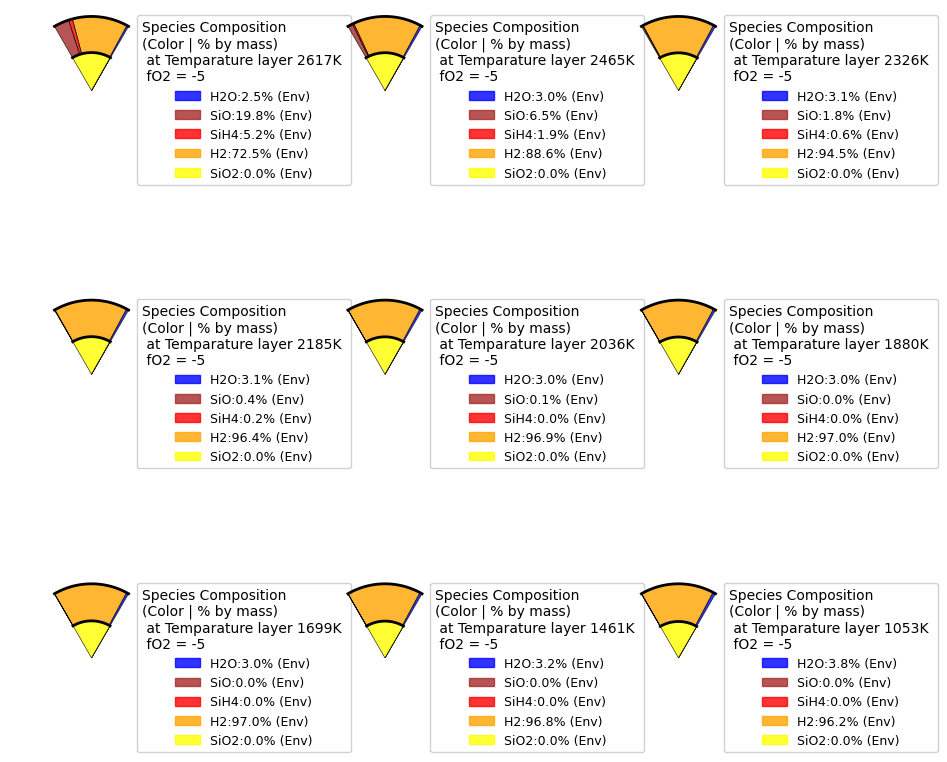

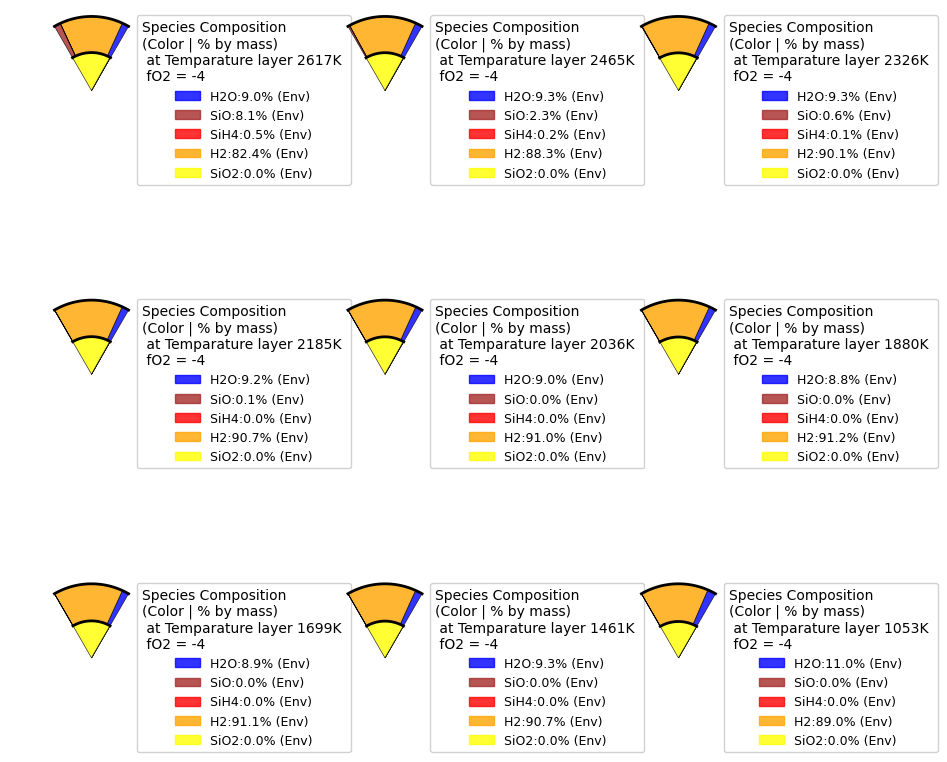

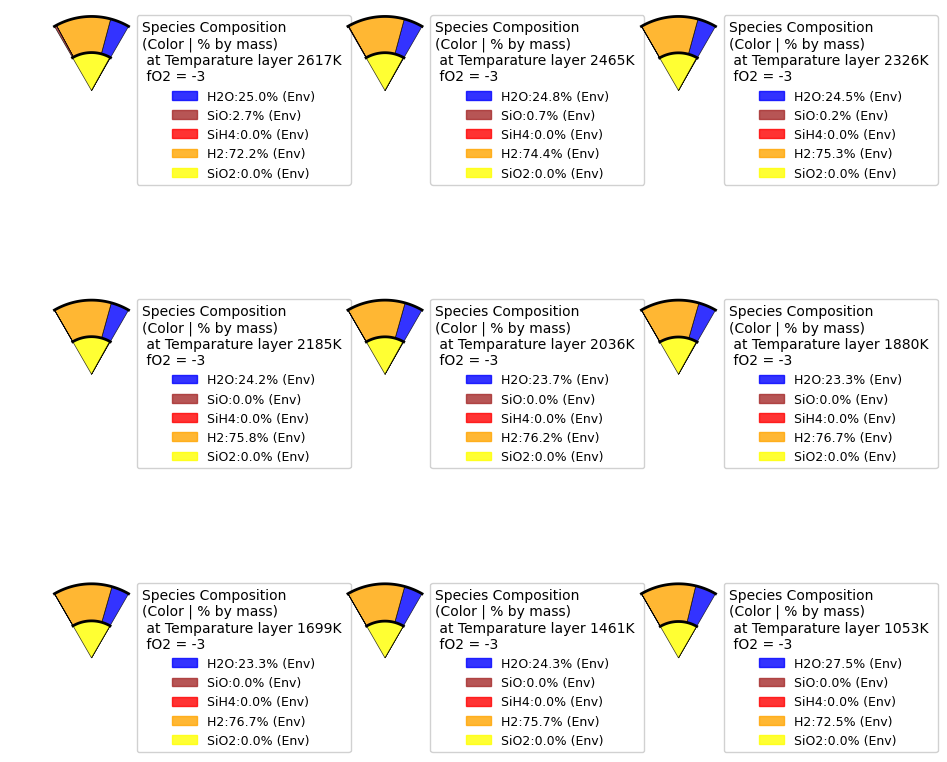

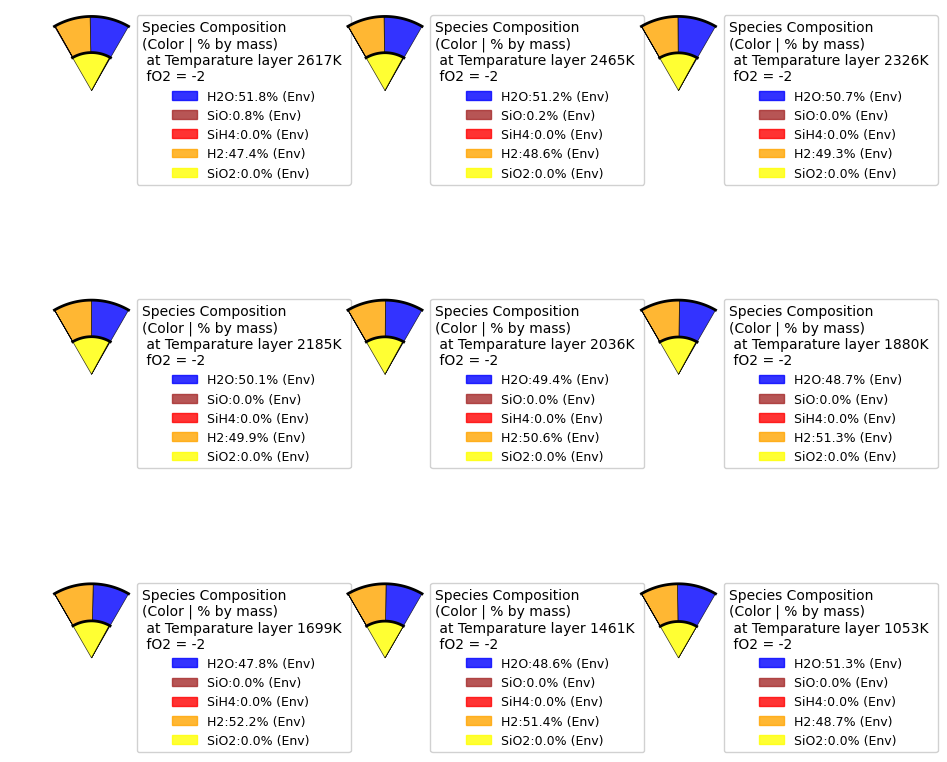

In [31]:
# Normalizing
def normalize_dict(comp_dict):
    total = sum(comp_dict.values())
    return {k: (v/total)*100 for k, v in comp_dict.items()}

fO2_log10_shifts = [-5, -4,-3,-2]
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    fig, axes = plt.subplots(3, 3, figsize=(12, 10))
    mantle_melt_fractions = [1]
    init_metallicitys = [1]
    init_metallicity = 1
    for i, ax in enumerate(axes.flat):
        filename = f"./excel_Uranus_time/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_T{Temperatures_layer_time.iloc[i]:.4g}K.xlsx"
        H2O_atmosphere_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
        H2_atmosphere_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
        O2_atmosphere_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
        SiO_atmosphere_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
        SiH4_atmosphere_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
        tot_atmosphere_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"] - pd.read_excel(filename, sheet_name="state")["mantle_mass"]

        H2O_mantle_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
        H2_mantle_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
        O2_mantle_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
        SiO_mantle_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
        SiH4_mantle_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
        SiO2_mantle_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
        tot_mantle_mass = pd.read_excel(filename, sheet_name="state")["mantle_mass"]

        H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
        H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
        O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
        SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
        SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
        SiO2_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]

        tot_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"]

        H2O_envelope_perc = H2O_atmosphere_mass/tot_atmosphere_mass
        H2_envelope_perc = H2_atmosphere_mass/tot_atmosphere_mass
        O2_envelope_perc = O2_atmosphere_mass/tot_atmosphere_mass
        SiO_envelope_perc = SiO_atmosphere_mass/tot_atmosphere_mass
        SiH4_envelope_perc = SiH4_atmosphere_mass/tot_atmosphere_mass

        H2O_mantle_perc = H2O_mantle_mass/tot_mantle_mass
        H2_mantle_perc = H2_mantle_mass/tot_mantle_mass
        O2_mantle_perc = O2_mantle_mass/tot_mantle_mass
        SiO_mantle_perc = SiO_mantle_mass/tot_mantle_mass
        SiH4_mantle_perc = SiH4_mantle_mass/tot_mantle_mass
        SiO2_mantle_perc = SiO2_mantle_mass/tot_mantle_mass


        H2O_perc = H2O_mass/tot_mass
        H2_perc = H2_mass/tot_mass
        O2_perc = O2_mass/tot_mass
        SiO_perc = SiO_mass/tot_mass
        SiH4_perc = SiH4_mass/tot_mass
        SiO2_perc = SiO2_mass/tot_mass


        # Core composition
        core_composition = {
            'H2O': H2O_mantle_perc[0]*100,
            'H2': H2_mantle_perc[0]*100,
            'SiH4': SiH4_mantle_perc[0]*100,   # adjust these to sum to 100
            'SiO': SiO_mantle_perc[0]*100,
            'SiO2': SiO2_mantle_perc[0]*100,
        }

        # Envelope composition
        envelope_composition = {
            'H2O': H2O_envelope_perc[0]*100,
            'H2': H2_envelope_perc[0]*100,
            'SiH4': SiH4_envelope_perc[0]*100,   # adjust these to sum to 100
            'SiO': SiO_envelope_perc[0]*100,
        }

        # Total composition
        total_composition = {
            'H2O': H2O_perc[0]*100,
            'H2': H2_perc[0]*100,
            'SiH4': SiH4_perc[0]*100,   # adjust these to sum to 100
            'SiO': SiO_perc[0]*100,
            'SiO2': SiO2_perc[0]*100,
        }


        core_comp = normalize_dict(core_composition)
        env_comp = normalize_dict(envelope_composition)
        total_comp = normalize_dict(total_composition)

        # Species colors
        species_colors = {
            'SiO2': 'yellow',
            'H2O': 'blue',
            'SiH4': 'red',
            'SiO': 'brown',
            'O2': 'limegreen',
            'H2': 'orange',
            'CO2': 'cyan',
            'CO' : 'magenta',
            'He': 'gray',
            'N2': 'green',
            'CH4': 'purple',
            'NH3': 'pink',
            'MgO': 'darkred',
            'MgH2': 'gold',
            'MgH' :'teal',
            'MgOH' : 'indigo'
        
        }

        # Parameters pie chart-
        theta1, theta2 = 60, 120 # 20-degree wedge
        core_radius = Radii_time.iloc[i]/3.939  # Core extends to 0.2 R_U
        total_radius = 1.0

        # Convert composition dicts to lists
        core_species = list(core_comp.keys())
        core_percents = list(core_comp.values())
        env_species = list(env_comp.keys())
        env_percents = list(env_comp.values())

        # draw different partitions starting with core
        core_start = 0.0
        cumulative = 0.0

        for j, (species, percent) in enumerate(zip(core_species, core_percents)):
            angle_width = (theta2 - theta1) * (percent / 100)
            angle_start = theta1 + cumulative * (theta2 - theta1) / 100
            angle_end = angle_start + angle_width
    
            wedge = plt.matplotlib.patches.Wedge(
                (0, 0), core_radius,
                angle_start, angle_end,
                facecolor=species_colors.get(species, 'gray'),
                edgecolor='black',
                linewidth=0.5,
                alpha=0.8
            )
            ax.add_patch(wedge)
    
            mid_angle = (angle_start + angle_end) / 2
            label_r = core_radius / 2
            label_theta = np.radians(mid_angle)
            x = label_r * np.cos(label_theta) * 1.1
            y = label_r * np.sin(label_theta)
            cumulative += percent

        cumulative = 0.0

        for j, (species, percent) in enumerate(zip(env_species, env_percents)):
            angle_width = (theta2 - theta1) * (percent / 100)
            angle_start = theta1 + cumulative * (theta2 - theta1) / 100
            angle_end = angle_start + angle_width
    
            annulus = plt.matplotlib.patches.Wedge(
                (0, 0), total_radius,
                angle_start, angle_end,
                width=total_radius - core_radius,
                facecolor=species_colors.get(species, 'gray'),
                edgecolor='black',
                linewidth=0.5,
                alpha=0.8
            )
            ax.add_patch(annulus)
    
            mid_angle = (angle_start + angle_end) / 2
            label_r = (core_radius + total_radius) / 2
            label_theta = np.radians(mid_angle)
            x = label_r * np.cos(label_theta) * 1.1
            y = label_r * np.sin(label_theta)
            cumulative += percent

        theta_line = np.linspace(np.radians(theta1), np.radians(theta2), 100)
        x_core = core_radius * np.cos(theta_line)
        y_core = core_radius * np.sin(theta_line)
        ax.plot(x_core, y_core, 'k-', linewidth=2)

        x_outer = total_radius * np.cos(theta_line)
        y_outer = total_radius * np.sin(theta_line)
        ax.plot(x_outer, y_outer, 'k-', linewidth=2)

        legend_entries = []

        # Species that appear in one
        for species in set(core_species) or set(env_species):
            core_p = core_comp.get(species, 0)
            env_p = env_comp.get(species, 0)
            tot_p = total_comp.get(species, 0)
            if core_p > 0 or env_p > 0:
                legend_entries.append(
                    (species_colors[species], 
                     f"{species}:{env_p:.1f}% (Env)")
                )

        # Create legend patches
        legend_patches = [
            Patch(color=color, label=label, alpha=0.8)
            for color, label in legend_entries
        ]

        # Add legend
        ax.legend(handles=legend_patches, 
                  loc='upper left', 
                  bbox_to_anchor=(0.74, 1),
                  title=f"Species Composition\n(Color | % by mass) \n at Temparature layer {Temperatures_layer_time.iloc[i]:.4g}K \n fO2 = {shift}",
                  fontsize=9,
                  title_fontsize=10,
                  framealpha=0.9)

        # --- FINISH PLOT ---
        ax.set_xlim(-1.1, 1.1)  # Extra space for legend
        ax.set_ylim(-0.1, 1.1)
        ax.set_aspect('equal')
        ax.axis('off')
    plt.subplots_adjust(wspace=0.8, hspace=0.4)
    plt.subplots_adjust(right=0.75, wspace=0.8, hspace=0.4)
    plt.show()

#horizontal axis = temperatures
#vertical axis = partial pressures of species

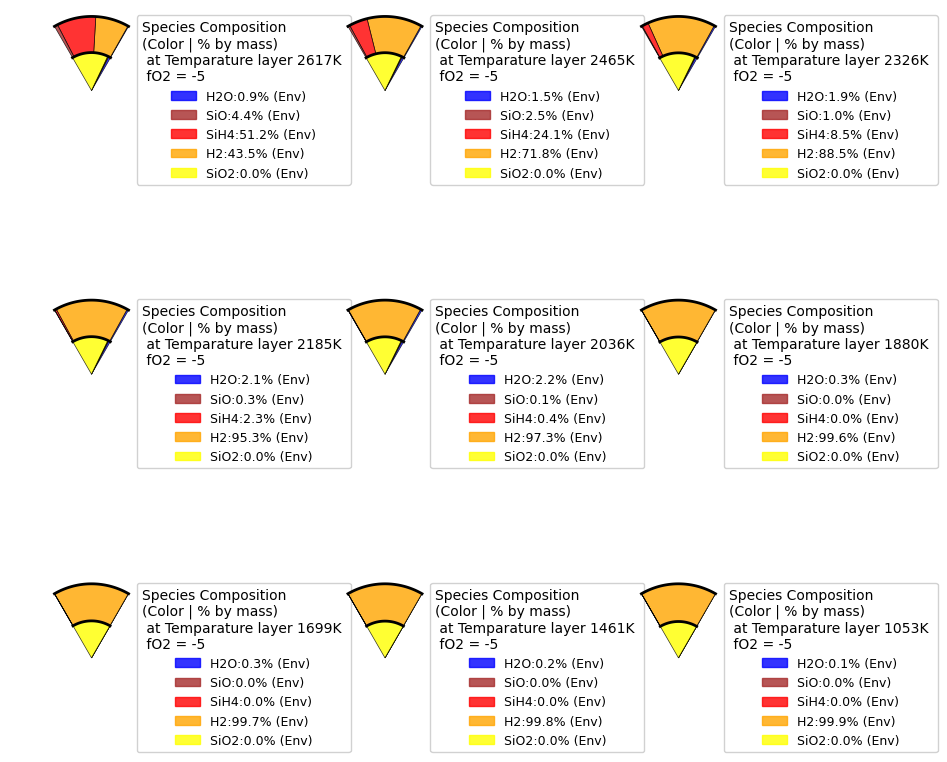

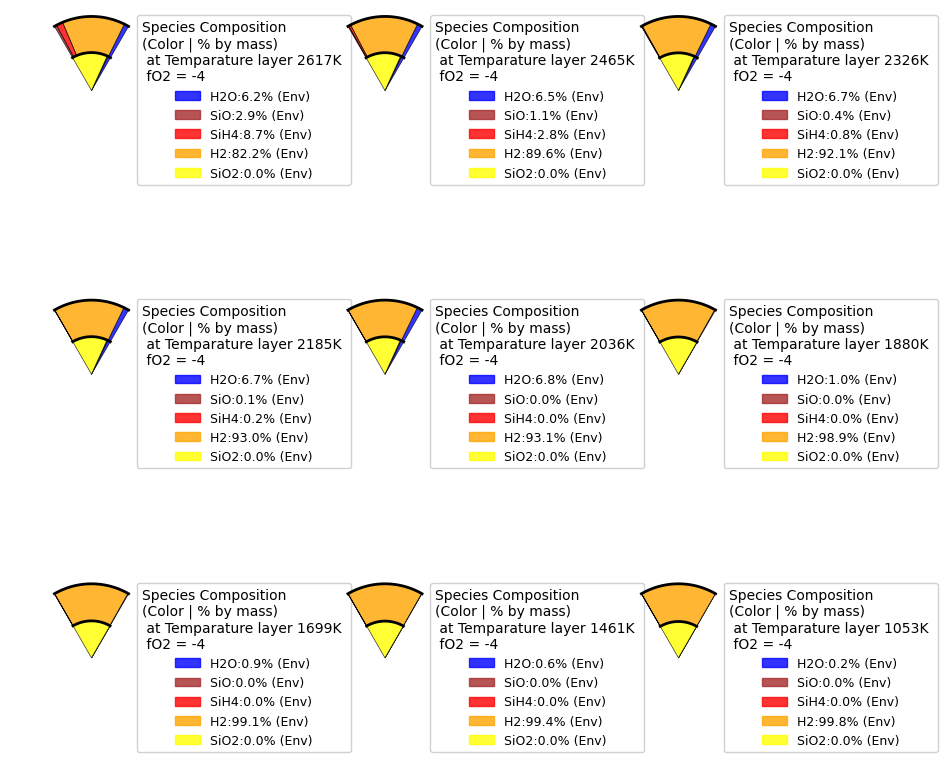

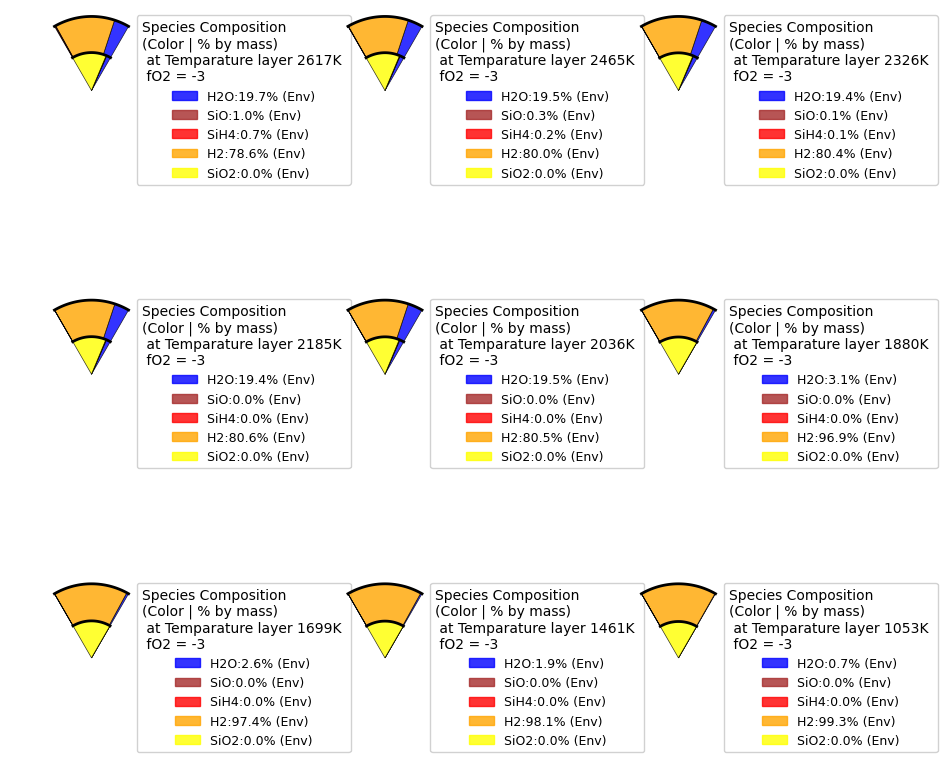

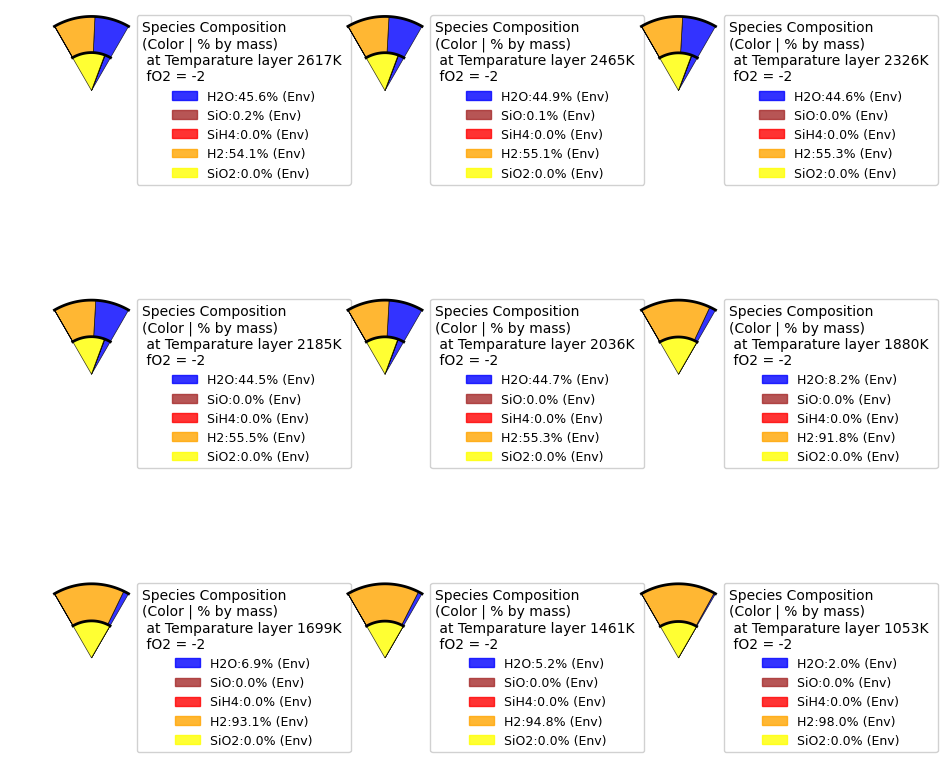

In [32]:
# Normalizing
def normalize_dict(comp_dict):
    total = sum(comp_dict.values())
    return {k: (v/total)*100 for k, v in comp_dict.items()}

fO2_log10_shifts = [-5, -4,-3,-2]
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    fig, axes = plt.subplots(3, 3, figsize=(12, 10))
    mantle_melt_fractions = [1]
    init_metallicitys = [1]
    init_metallicity = 1
    for i, ax in enumerate(axes.flat):
        filename = f"./excel_Uranus_time/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_T{Temperatures_layer_time.iloc[i]:.4g}K.xlsx"
        H2O_atmosphere_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
        H2_atmosphere_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
        O2_atmosphere_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
        SiO_atmosphere_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
        SiH4_atmosphere_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
        tot_atmosphere_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"] - pd.read_excel(filename, sheet_name="state")["mantle_mass"]

        H2O_mantle_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
        H2_mantle_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
        O2_mantle_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
        SiO_mantle_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
        SiH4_mantle_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
        SiO2_mantle_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
        tot_mantle_mass = pd.read_excel(filename, sheet_name="state")["mantle_mass"]

        H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
        H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
        O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
        SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
        SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
        SiO2_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]

        tot_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"]

        H2O_envelope_perc = H2O_atmosphere_mass/tot_atmosphere_mass
        H2_envelope_perc = H2_atmosphere_mass/tot_atmosphere_mass
        O2_envelope_perc = O2_atmosphere_mass/tot_atmosphere_mass
        SiO_envelope_perc = SiO_atmosphere_mass/tot_atmosphere_mass
        SiH4_envelope_perc = SiH4_atmosphere_mass/tot_atmosphere_mass

        H2O_mantle_perc = H2O_mantle_mass/tot_mantle_mass
        H2_mantle_perc = H2_mantle_mass/tot_mantle_mass
        O2_mantle_perc = O2_mantle_mass/tot_mantle_mass
        SiO_mantle_perc = SiO_mantle_mass/tot_mantle_mass
        SiH4_mantle_perc = SiH4_mantle_mass/tot_mantle_mass
        SiO2_mantle_perc = SiO2_mantle_mass/tot_mantle_mass


        H2O_perc = H2O_mass/tot_mass
        H2_perc = H2_mass/tot_mass
        O2_perc = O2_mass/tot_mass
        SiO_perc = SiO_mass/tot_mass
        SiH4_perc = SiH4_mass/tot_mass
        SiO2_perc = SiO2_mass/tot_mass


        # Core composition
        core_composition = {
            'H2O': H2O_mantle_perc.iloc[-1]*100,
            'H2': H2_mantle_perc.iloc[-1]*100,
            'SiH4': SiH4_mantle_perc.iloc[-1]*100,   # adjust these to sum to 100
            'SiO': SiO_mantle_perc.iloc[-1]*100,
            'SiO2': SiO2_mantle_perc.iloc[-1]*100,
        }

        # Envelope composition
        envelope_composition = {
            'H2O': H2O_envelope_perc.iloc[-1]*100,
            'H2': H2_envelope_perc.iloc[-1]*100,
            'SiH4': SiH4_envelope_perc.iloc[-1]*100,   # adjust these to sum to 100
            'SiO': SiO_envelope_perc.iloc[-1]*100,
        }

        # Total composition
        total_composition = {
            'H2O': H2O_perc.iloc[-1]*100,
            'H2': H2_perc.iloc[-1]*100,
            'SiH4': SiH4_perc.iloc[-1]*100,   # adjust these to sum to 100
            'SiO': SiO_perc.iloc[-1]*100,
            'SiO2': SiO2_perc.iloc[-1]*100,
        }


        core_comp = normalize_dict(core_composition)
        env_comp = normalize_dict(envelope_composition)
        total_comp = normalize_dict(total_composition)

        # Species colors
        species_colors = {
            'SiO2': 'yellow',
            'H2O': 'blue',
            'SiH4': 'red',
            'SiO': 'brown',
            'O2': 'limegreen',
            'H2': 'orange',
            'CO2': 'cyan',
            'CO' : 'magenta',
            'He': 'gray',
            'N2': 'green',
            'CH4': 'purple',
            'NH3': 'pink',
            'MgO': 'darkred',
            'MgH2': 'gold',
            'MgH' :'teal',
            'MgOH' : 'indigo'
        
        }

        # Parameters pie chart-
        theta1, theta2 = 60, 120 # 20-degree wedge
        core_radius = Radii_time.iloc[i]/3.939  # Core extends to 0.2 R_U
        total_radius = 1.0

        # Convert composition dicts to lists
        core_species = list(core_comp.keys())
        core_percents = list(core_comp.values())
        env_species = list(env_comp.keys())
        env_percents = list(env_comp.values())

        # draw different partitions starting with core
        core_start = 0.0
        cumulative = 0.0

        for j, (species, percent) in enumerate(zip(core_species, core_percents)):
            angle_width = (theta2 - theta1) * (percent / 100)
            angle_start = theta1 + cumulative * (theta2 - theta1) / 100
            angle_end = angle_start + angle_width
    
            wedge = plt.matplotlib.patches.Wedge(
                (0, 0), core_radius,
                angle_start, angle_end,
                facecolor=species_colors.get(species, 'gray'),
                edgecolor='black',
                linewidth=0.5,
                alpha=0.8
            )
            ax.add_patch(wedge)
    
            mid_angle = (angle_start + angle_end) / 2
            label_r = core_radius / 2
            label_theta = np.radians(mid_angle)
            x = label_r * np.cos(label_theta) * 1.1
            y = label_r * np.sin(label_theta)
            cumulative += percent

        cumulative = 0.0

        for j, (species, percent) in enumerate(zip(env_species, env_percents)):
            angle_width = (theta2 - theta1) * (percent / 100)
            angle_start = theta1 + cumulative * (theta2 - theta1) / 100
            angle_end = angle_start + angle_width
    
            annulus = plt.matplotlib.patches.Wedge(
                (0, 0), total_radius,
                angle_start, angle_end,
                width=total_radius - core_radius,
                facecolor=species_colors.get(species, 'gray'),
                edgecolor='black',
                linewidth=0.5,
                alpha=0.8
            )
            ax.add_patch(annulus)
    
            mid_angle = (angle_start + angle_end) / 2
            label_r = (core_radius + total_radius) / 2
            label_theta = np.radians(mid_angle)
            x = label_r * np.cos(label_theta) * 1.1
            y = label_r * np.sin(label_theta)
            cumulative += percent

        theta_line = np.linspace(np.radians(theta1), np.radians(theta2), 100)
        x_core = core_radius * np.cos(theta_line)
        y_core = core_radius * np.sin(theta_line)
        ax.plot(x_core, y_core, 'k-', linewidth=2)

        x_outer = total_radius * np.cos(theta_line)
        y_outer = total_radius * np.sin(theta_line)
        ax.plot(x_outer, y_outer, 'k-', linewidth=2)

        legend_entries = []

        # Species that appear in one
        for species in set(core_species) or set(env_species):
            core_p = core_comp.get(species, 0)
            env_p = env_comp.get(species, 0)
            tot_p = total_comp.get(species, 0)
            if core_p > 0 or env_p > 0:
                legend_entries.append(
                    (species_colors[species], 
                     f"{species}:{env_p:.1f}% (Env)")
                )

        # Create legend patches
        legend_patches = [
            Patch(color=color, label=label, alpha=0.8)
            for color, label in legend_entries
        ]

        # Add legend
        ax.legend(handles=legend_patches, 
                  loc='upper left', 
                  bbox_to_anchor=(0.74, 1),
                  title=f"Species Composition\n(Color | % by mass) \n at Temparature layer {Temperatures_layer_time.iloc[i]:.4g}K \n fO2 = {shift}",
                  fontsize=9,
                  title_fontsize=10,
                  framealpha=0.9)

        # --- FINISH PLOT ---
        ax.set_xlim(-1.1, 1.1)  # Extra space for legend
        ax.set_ylim(-0.1, 1.1)
        ax.set_aspect('equal')
        ax.axis('off')
    plt.subplots_adjust(wspace=0.8, hspace=0.4)
    plt.subplots_adjust(right=0.75, wspace=0.8, hspace=0.4)
    plt.show()

    #SiH4 half -> silicon bearing molecules will condens when temperature decrease, SiH4 will suddenly decrease 

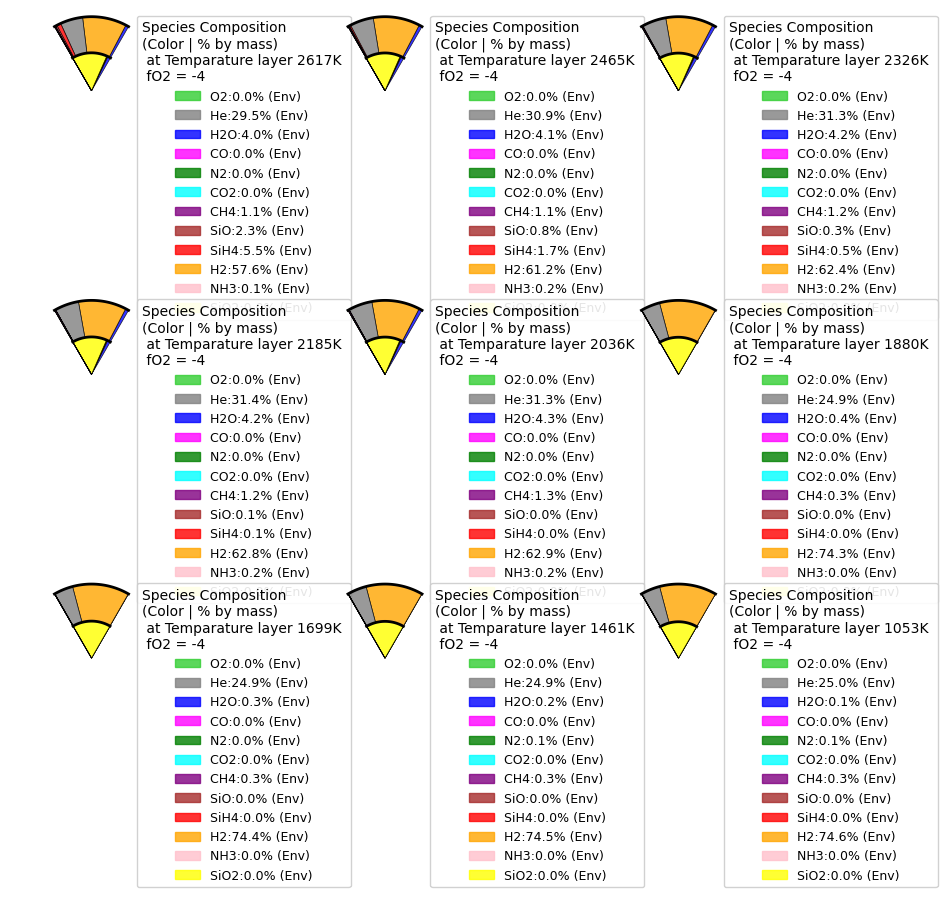

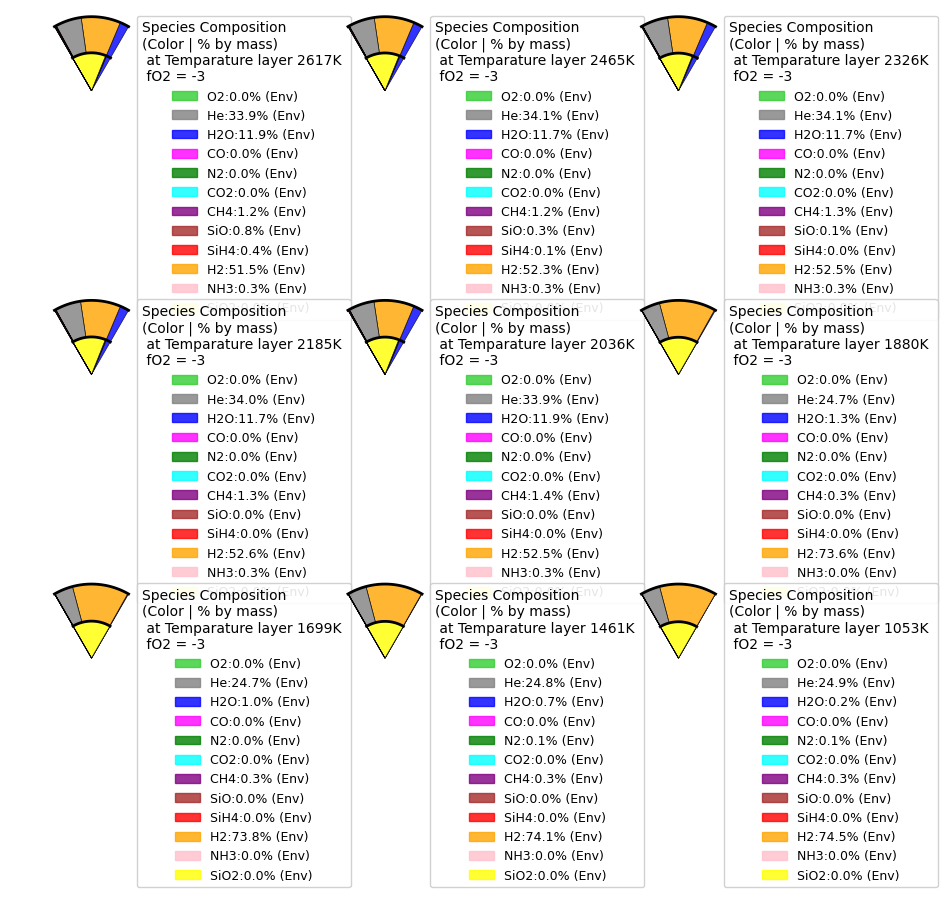

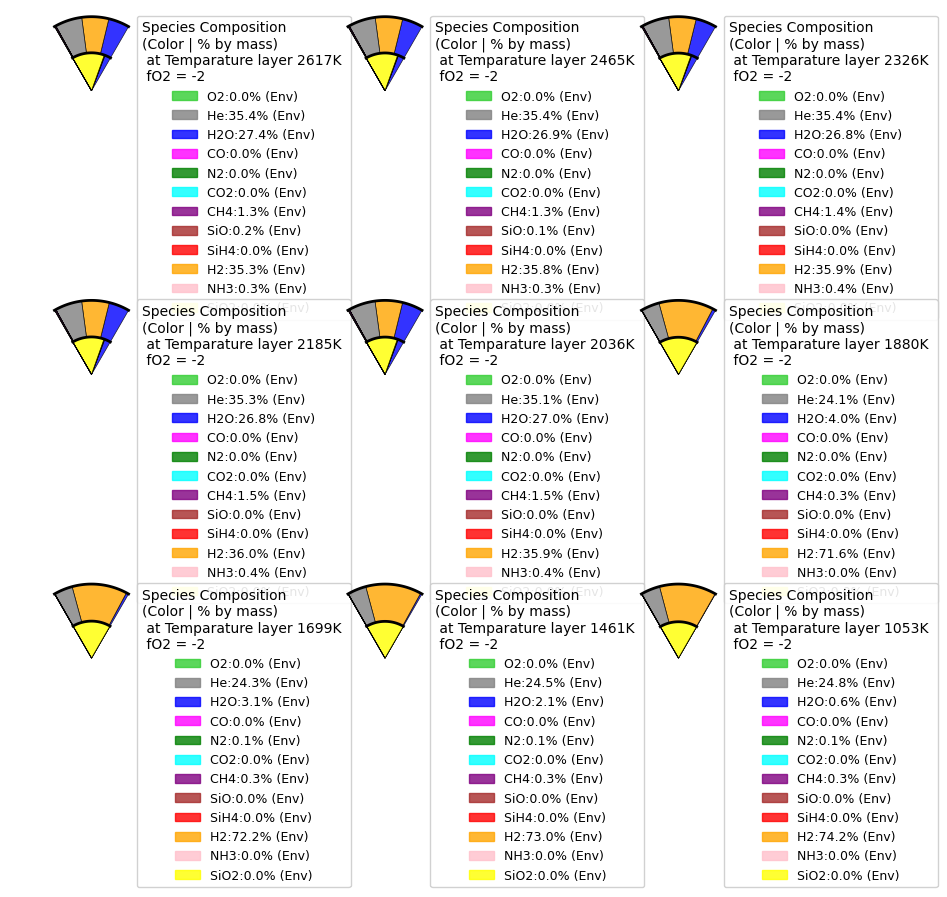

In [30]:
# Normalizing
def normalize_dict(comp_dict):
    total = sum(comp_dict.values())
    return {k: (v/total)*100 for k, v in comp_dict.items()}

fO2_log10_shifts = [-4,-3,-2]
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    fig, axes = plt.subplots(3, 3, figsize=(12, 10))
    mantle_melt_fractions = [1]
    init_metallicitys = [1]
    init_metallicity = 1
    for i, ax in enumerate(axes.flat):
        filename = f"./excel_Uranus_time/HHeCNOSi/rho{rho_centre}/core_boundary/HHeCNOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_T{Temperatures_layer_time.iloc[i]:.4g}K.xlsx"
        H2O_atmosphere_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
        H2_atmosphere_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
        O2_atmosphere_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
        SiO_atmosphere_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
        SiH4_atmosphere_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
        He_atmosphere_mass = pd.read_excel(filename, sheet_name="He_g")["gas_mass"]
        CO2_atmosphere_mass = pd.read_excel(filename, sheet_name="CO2_g")["gas_mass"]
        CO_atmosphere_mass = pd.read_excel(filename, sheet_name="CO_g")["gas_mass"]
        CH4_atmosphere_mass = pd.read_excel(filename, sheet_name="CH4_g")["gas_mass"]
        N2_atmosphere_mass = pd.read_excel(filename, sheet_name="N2_g")["gas_mass"]
        NH3_atmosphere_mass = pd.read_excel(filename, sheet_name="H3N_g")["gas_mass"]
        tot_atmosphere_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"] - pd.read_excel(filename, sheet_name="state")["mantle_mass"]

        H2O_mantle_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
        H2_mantle_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
        O2_mantle_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
        SiO_mantle_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
        SiH4_mantle_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
        He_mantle_mass = pd.read_excel(filename, sheet_name="He_g")["dissolved_mass"]
        CO2_mantle_mass = pd.read_excel(filename, sheet_name="CO2_g")["dissolved_mass"]
        CO_mantle_mass = pd.read_excel(filename, sheet_name="CO_g")["dissolved_mass"]
        CH4_mantle_mass = pd.read_excel(filename, sheet_name="CH4_g")["dissolved_mass"]
        N2_mantle_mass = pd.read_excel(filename, sheet_name="N2_g")["dissolved_mass"]
        NH3_mantle_mass = pd.read_excel(filename, sheet_name="H3N_g")["dissolved_mass"]
        SiO2_mantle_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
        tot_mantle_mass = pd.read_excel(filename, sheet_name="state")["mantle_mass"]

        H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
        H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
        O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
        SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
        SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
        He_mass = pd.read_excel(filename, sheet_name="He_g")["total_mass"]
        CO2_mass = pd.read_excel(filename, sheet_name="CO2_g")["total_mass"]
        CO_mass = pd.read_excel(filename, sheet_name="CO_g")["total_mass"]
        CH4_mass = pd.read_excel(filename, sheet_name="CH4_g")["total_mass"]
        N2_mass = pd.read_excel(filename, sheet_name="N2_g")["total_mass"]
        NH3_mass = pd.read_excel(filename, sheet_name="H3N_g")["total_mass"]
        SiO2_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]

        tot_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"]

        H2O_envelope_perc = H2O_atmosphere_mass/tot_atmosphere_mass
        H2_envelope_perc = H2_atmosphere_mass/tot_atmosphere_mass
        O2_envelope_perc = O2_atmosphere_mass/tot_atmosphere_mass
        SiO_envelope_perc = SiO_atmosphere_mass/tot_atmosphere_mass
        SiH4_envelope_perc = SiH4_atmosphere_mass/tot_atmosphere_mass
        He_envelope_perc = He_atmosphere_mass/tot_atmosphere_mass
        CO2_envelope_perc = CO2_atmosphere_mass/tot_atmosphere_mass
        CO_envelope_perc = CO_atmosphere_mass/tot_atmosphere_mass
        CH4_envelope_perc = CH4_atmosphere_mass/tot_atmosphere_mass
        N2_envelope_perc = N2_atmosphere_mass/tot_atmosphere_mass
        NH3_envelope_perc = NH3_atmosphere_mass/tot_atmosphere_mass

        H2O_mantle_perc = H2O_mantle_mass/tot_mantle_mass
        H2_mantle_perc = H2_mantle_mass/tot_mantle_mass
        O2_mantle_perc = O2_mantle_mass/tot_mantle_mass
        SiO_mantle_perc = SiO_mantle_mass/tot_mantle_mass
        SiH4_mantle_perc = SiH4_mantle_mass/tot_mantle_mass
        He_mantle_perc = He_mantle_mass/tot_mantle_mass
        CO2_mantle_perc = CO2_mantle_mass/tot_mantle_mass
        CO_mantle_perc = CO_mantle_mass/tot_mantle_mass
        CH4_mantle_perc = CH4_mantle_mass/tot_mantle_mass
        N2_mantle_perc = N2_mantle_mass/tot_mantle_mass
        NH3_mantle_perc = NH3_mantle_mass/tot_mantle_mass
        SiO2_mantle_perc = SiO2_mantle_mass/tot_mantle_mass


        H2O_perc = H2O_mass/tot_mass
        H2_perc = H2_mass/tot_mass
        O2_perc = O2_mass/tot_mass
        SiO_perc = SiO_mass/tot_mass
        SiH4_perc = SiH4_mass/tot_mass
        He_perc = He_mass/tot_mass
        CO2_perc = CO2_mass/tot_mass
        CO_perc = CO_mass/tot_mass
        CH4_perc = CH4_mass/tot_mass
        N2_perc = N2_mass/tot_mass
        NH3_perc = NH3_mass/tot_mass
        SiO2_perc = SiO2_mass/tot_mass


        # Core composition
        core_composition = {
            'H2O': H2O_mantle_perc.iloc[-1]*100,
            'H2': H2_mantle_perc.iloc[-1]*100,
            'He': He_mantle_perc.iloc[-1]*100,
            'SiH4': SiH4_mantle_perc.iloc[-1]*100,   # adjust these to sum to 100
            'SiO': SiO_mantle_perc.iloc[-1]*100,
            'SiO2': SiO2_mantle_perc.iloc[-1]*100,
            'O2': O2_mantle_perc.iloc[-1]*100,
            'CO2': CO2_mantle_perc.iloc[-1]*100,
            'CO': CO_mantle_perc.iloc[-1]*100,
            'CH4': CH4_mantle_perc.iloc[-1]*100,
            'N2': N2_mantle_perc.iloc[-1]*100,
            'NH3' : NH3_mantle_perc.iloc[-1]*100
        }

        # Envelope composition
        envelope_composition = {
            'H2O': H2O_envelope_perc.iloc[-1]*100,
            'H2': H2_envelope_perc.iloc[-1]*100,
            'He': He_envelope_perc.iloc[-1]*100,
            'SiH4': SiH4_envelope_perc.iloc[-1]*100,   # adjust these to sum to 100
            'SiO': SiO_envelope_perc.iloc[-1]*100,
            'O2': O2_envelope_perc.iloc[-1]*100,
            'CO2': CO2_envelope_perc.iloc[-1]*100,
            'CO': CO_envelope_perc.iloc[-1]*100,
            'CH4': CH4_envelope_perc.iloc[-1]*100,
            'N2': N2_envelope_perc.iloc[-1]*100,
            'NH3' : NH3_envelope_perc.iloc[-1]*100
        }

        # Total composition
        total_composition = {
            'H2O': H2O_perc.iloc[-1]*100,
            'H2': H2_perc.iloc[-1]*100,
            'He': He_perc.iloc[-1]*100,
            'SiH4': SiH4_perc.iloc[-1]*100,   # adjust these to sum to 100
            'SiO': SiO_perc.iloc[-1]*100,
            'SiO2': SiO2_perc.iloc[-1]*100,
            'O2': O2_perc.iloc[-1]*100,
            'CO2': CO2_perc.iloc[-1]*100,
            'CO': CO_perc.iloc[-1]*100,
            'CH4': CH4_perc.iloc[-1]*100,
            'N2': N2_perc.iloc[-1]*100,
            'NH3' : NH3_perc.iloc[-1]*100
        }


        core_comp = normalize_dict(core_composition)
        env_comp = normalize_dict(envelope_composition)
        total_comp = normalize_dict(total_composition)

        # Species colors
        species_colors = {
            'SiO2': 'yellow',
            'H2O': 'blue',
            'SiH4': 'red',
            'SiO': 'brown',
            'O2': 'limegreen',
            'H2': 'orange',
            'CO2': 'cyan',
            'CO' : 'magenta',
            'He': 'gray',
            'N2': 'green',
            'CH4': 'purple',
            'NH3': 'pink',
            'MgO': 'darkred',
            'MgH2': 'gold',
            'MgH' :'teal',
            'MgOH' : 'indigo'
        
        }

        # Parameters pie chart-
        theta1, theta2 = 60, 120 # 20-degree wedge
        core_radius = Radii_time.iloc[i]/3.939  # Core extends to 0.2 R_U
        total_radius = 1.0

        # Convert composition dicts to lists
        core_species = list(core_comp.keys())
        core_percents = list(core_comp.values())
        env_species = list(env_comp.keys())
        env_percents = list(env_comp.values())

        # draw different partitions starting with core
        core_start = 0.0
        cumulative = 0.0

        for j, (species, percent) in enumerate(zip(core_species, core_percents)):
            angle_width = (theta2 - theta1) * (percent / 100)
            angle_start = theta1 + cumulative * (theta2 - theta1) / 100
            angle_end = angle_start + angle_width
    
            wedge = plt.matplotlib.patches.Wedge(
                (0, 0), core_radius,
                angle_start, angle_end,
                facecolor=species_colors.get(species, 'gray'),
                edgecolor='black',
                linewidth=0.5,
                alpha=0.8
            )
            ax.add_patch(wedge)
    
            mid_angle = (angle_start + angle_end) / 2
            label_r = core_radius / 2
            label_theta = np.radians(mid_angle)
            x = label_r * np.cos(label_theta) * 1.1
            y = label_r * np.sin(label_theta)
            cumulative += percent

        cumulative = 0.0

        for j, (species, percent) in enumerate(zip(env_species, env_percents)):
            angle_width = (theta2 - theta1) * (percent / 100)
            angle_start = theta1 + cumulative * (theta2 - theta1) / 100
            angle_end = angle_start + angle_width
    
            annulus = plt.matplotlib.patches.Wedge(
                (0, 0), total_radius,
                angle_start, angle_end,
                width=total_radius - core_radius,
                facecolor=species_colors.get(species, 'gray'),
                edgecolor='black',
                linewidth=0.5,
                alpha=0.8
            )
            ax.add_patch(annulus)
    
            mid_angle = (angle_start + angle_end) / 2
            label_r = (core_radius + total_radius) / 2
            label_theta = np.radians(mid_angle)
            x = label_r * np.cos(label_theta) * 1.1
            y = label_r * np.sin(label_theta)
            cumulative += percent

        theta_line = np.linspace(np.radians(theta1), np.radians(theta2), 100)
        x_core = core_radius * np.cos(theta_line)
        y_core = core_radius * np.sin(theta_line)
        ax.plot(x_core, y_core, 'k-', linewidth=2)

        x_outer = total_radius * np.cos(theta_line)
        y_outer = total_radius * np.sin(theta_line)
        ax.plot(x_outer, y_outer, 'k-', linewidth=2)

        legend_entries = []

        # Species that appear in one
        for species in set(core_species) or set(env_species):
            core_p = core_comp.get(species, 0)
            env_p = env_comp.get(species, 0)
            tot_p = total_comp.get(species, 0)
            if core_p > 0 or env_p > 0:
                legend_entries.append(
                    (species_colors[species], 
                     f"{species}:{env_p:.1f}% (Env)")
                )

        # Create legend patches
        legend_patches = [
            Patch(color=color, label=label, alpha=0.8)
            for color, label in legend_entries
        ]

        # Add legend
        ax.legend(handles=legend_patches, 
                  loc='upper left', 
                  bbox_to_anchor=(0.74, 1),
                  title=f"Species Composition\n(Color | % by mass) \n at Temparature layer {Temperatures_layer_time.iloc[i]:.4g}K \n fO2 = {shift}",
                  fontsize=9,
                  title_fontsize=10,
                  framealpha=0.9)

        # --- FINISH PLOT ---
        ax.set_xlim(-1.1, 1.1)  # Extra space for legend
        ax.set_ylim(-0.1, 1.1)
        ax.set_aspect('equal')
        ax.axis('off')
    plt.subplots_adjust(wspace=0.8, hspace=0.4)
    plt.subplots_adjust(right=0.75, wspace=0.8, hspace=0.4)
    plt.show()